# 09. MRAC integration: nominal loaded reference and mismatched plant

**EXPLORATORY / offline / PROXY.** This notebook explains and uses the existing A0 implementation, not a new damper. It compares a nominal loaded reference using PID+FF+linear damping, a mismatched plant using that same direct baseline, and a mismatched plant following the loaded reference with adaptation. A frozen-estimate A0 arm isolates the adaptation switch.

The default execution reads existing summary data only. It does not roll out, tune, train, overwrite results, or load a PPO policy. The trajectories function at the end must be called only after a separate run approval.

**Sources and terms.** **MQP** is the thesis derivation note *MRAC for a planar quadrotor with a cable-suspended payload* (`.ai/research/derivations/mrac-quadrotor-payload.md`, status PROPOSED, not accepted); "MQP §x" means section x of it, and the steps used here are re-derived in this notebook and in notebooks 05 and 07. The full glossary is in `00_Notation_and_Reading_Guide.ipynb`.

| Term | Meaning here |
|---|---|
| A0 | the first MRAC architecture of the plan (MQP §1.2): a frozen nominal reference closed loop and the real plant run in parallel, and an adaptive law makes the plant follow the reference |
| nominal loaded reference | the A0 reference carries the **nominal payload** (4 kg, 2 m), the load on which the law was tuned (MQP §6.13, wave W2d); explained in section 1.1 |
| direct baseline (`softer`) | arm 2: PID+FF with the softer swing law acting on the **plant** torque, no MRAC |
| A0 FROZEN, A0 ONLINE | the A0 arm with the adaptive estimates fixed at the nominal values (FROZEN) or adapting (ONLINE) |
| arms 1-3 | arm 1 PID+FF with a mass-blind feedforward (assumes 4 kg); arm 2 adds the softer law and the damper; arm 3 is arm 2 plus MRAC |
| EQ-MR-nn | row IDs of the MRAC table of the thesis equation registry (all PROPOSED); EQ-MR-05..14 are the plant, the payload law and the nominal-payload reference, EQ-MR-15..21 the diagnostics and the later variants |
| C1, C2, C3 | the three mechanisms behind the long-horizon failure, section 9 |


### Notation used across this series (added 2026-11-25)

The thesis notation (`thesis_book/residual.tex`, lines 95-292) is primary. The code and the derivation document (MQP) use their own symbols, mapped in the thesis file `.ai/research/derivations/notation-residual-tex.md`.

| This notebook / code | residual.tex | Note |
|---|---|---|
| `m_L`, `l` | $m_b$, $\ell$ | payload mass, rope length |
| `m_q`, `J`; `f`, `tau` | $m_q$, $J_q$; $f_q$, $\tau_q$ | |
| `phi` (code) | $\varphi$ | **$\varphi_{\rm tex} = -\varphi_{\rm code}$** with the cable at the vehicle CoG ($d = 0$). Odd functions of $\varphi$ flip sign; $\cos\varphi$, the tension and the tangent do not. With an offset $d\ne0$ the map is nonlinear |
| task reference `p_r(t)` | $x^d$ ("reference state" in residual.tex) | not Guha's reference model $x_r$ |

Numbers in this notebook are unchanged; only the reading of the symbols is aligned.

### Offset-plant angle scope
The NB09 cached analyses use **code-angle** $\phi_{code}$ at $d=0.3795\,\mathrm{m}$. The simple residual.tex sign conversion $\varphi_{tex}=-\varphi_{code}$ is only valid at $d=0$ and must not be applied to these offset results. Tables and plots remain in code coordinates; no numeric data were transformed.


## 1. Models, assumptions and intended comparison

The model is planar and z-up. The load is a point mass on a rigid, massless cable; the model exits when tension is not positive. The reference has nominal vehicle and payload parameters. It uses its own swing and tension for its baseline, is initialized once, and evolves independently of the real plant. Here “real” means the mismatched **offline simulated plant**, not hardware.

| Arm | Plant | Damper location | Adaptation |
|---|---|---|---|
| Nominal reference | nominal vehicle and nominal load | reference | none |
| Direct baseline (`softer`) | mismatched load | plant torque | none |
| A0 FROZEN | mismatched load | reference only | off, nominal coefficients |
| A0 ONLINE | mismatched load | reference only | on |

The direct baseline and A0 arms do not have identical feedback architectures. ONLINE versus FROZEN changes the adaptation flags while keeping the A0 architecture. Comparing ONLINE with the direct baseline compares **complete controllers**, not adaptation alone. The cached data includes payload mass and cable-length mismatch, not A0 vehicle-mismatch results.

### 1.1 What "the reference carries the nominal payload" means, and why it changes what the law must learn (MQP §6.13)

> **Where this comes from.** Source: MQP §6.13, the A0 nominal-payload reference (wave W2d), built on §6.2-6.7 (notebook 07, section 4.3). Prerequisites: notebook 07, sections 4.1-4.3; notebook 05, section 4.4. Assumptions: the reference and the plant have the same attachment offset $d$ and the same cable length unless a case says otherwise; the swing law sits inside the reference only; the reference never reads the plant after its initialisation.

**Two choices of reference.**
* **No-load reference (notebook 07 sections 5-8, MQP §6.4).** The reference vehicle carries *no* payload, so it has no swing and no cable tension. The real vehicle carries $m_L$. Relative to this reference the whole payload is an unmodelled effect, and the law has to produce the payload force through its payload coefficients $\hat m_L,\hat\mu_L$ (initialised at 0).
* **Nominal loaded reference (A0, MQP §6.13).** The reference is a copy of the nominal vehicle *with* the nominal payload ($m_{L,r}=4$ kg, $l_r=2$ m, same $d$), under PID+FF (mass-blind $\hat m=4$ kg, its tension gate fed by the reference's **own** tension $T_r$) plus the softer swing law acting on the **reference** swing $\phi_r$. It has its own swing, its own tension and its own motor states, and it is stepped in parallel with the plant. After a one-time copy of the kinematic state at $t=0$ it never reads the plant again.

**What the law must learn changes.** Write $\tilde\Theta=\hat\Theta-\Theta^*$ (estimate minus the ideal coefficients that cancel the true plant, notebook 07 section 4.3.4). For the force rows with equal effectiveness, $\Theta_p^*=[m_q,m_L,\mu_L]/\kappa$.
* No-load reference, payload estimates started at 0: $\tilde\Theta_p(0)=-[0,\ m_L,\ \mu_L]/\kappa$, the **whole payload** is parameter error from the first tick, and $\Delta F=0$ is *not* a fixed point for $m_L>0$ (MQP §6.4).
* Nominal loaded reference, estimates started at the nominal ideals $[m_{q},\,4,\,8]$ (with $\mu_{L,r}=m_{L,r}l_r=8$ kg m): $\tilde\Theta_p(0)=[0,\ 4-m_L,\ 8-\mu_L]/\kappa$, only the **mismatch** from the nominal payload is parameter error. At the nominal load $(m_L,l)=(4\text{ kg},2\text{ m})$ it is exactly 0, the plant coincides with the reference, the correction is zero at every tick and no coefficient moves (the "nominal identity", MQP §6.13 item 4; unit-tested bit for bit).

The reference bracket $B_r$ (the wrench the reference's own balance demands, notebook 07 section 4.3.4) now contains the payload terms, so the reference defect $\rho_r$ stays a quantity of the reference only (section 2.1 gives the closed forms). Two consequences are visible in the saved results below: (i) the parameter error to be learned is smaller whenever the real payload is closer to the nominal one than to zero (for the mass coefficient, $m_L>2$ kg) and is zero at the nominal load (a statement about the initial parameter error only: the saved results below do not show a tracking benefit), but (ii) the plant's own swing $\phi$ now differs from the reference swing $\phi_r$, and since the swing law acts only inside the reference, the swing deviation $\phi-\phi_r$ is **measured but not damped** by the law. A *length* mismatch ($l\ne l_r$) breaks the argument altogether (the plant swing frequency differs from the reference's; the plan calls this Fact 2), which is why the length cases are a negative control.

**Intuition.** A model-reference law can only be asked to make the plant behave like the reference. If the reference is an unloaded vehicle, the law spends its effort faking a payload. If the reference already carries the payload we designed for, the law only has to absorb the difference between the real payload and the designed one.


## 2. Derivation: loaded reference and payload-aware tracking

> **Where this comes from.**
> * **Source:** MQP §5.3-5.6 (balances, tension, swing and elimination: notebook 05, sections 4.2-4.4), MQP §6.2-6.7 (route-(b) regressor, row split, cascade, error equation, adaptation: notebook 07, section 4.3 gives the steps) and MQP §6.13 (the A0 nominal-payload reference), with registry rows EQ-MR-05 through EQ-MR-14. These rows are **PROPOSED**. No assertion here upgrades them to a Pymunk, safety or stability result.
> * **Prerequisites:** notebook 07, sections 4.1-4.4, and section 1.1 above.
> * **Assumptions:** continuous time, ideal (unsaturated, lag-free) command for the identities; constant plant parameters; positive effectiveness; no wrap crossing; the ideal coefficients inside the projection boxes. None of these is established for the sampled, saturated closed loop.

The following restates the reduced-model identities (the derivation of the regressor columns and of the cancellation is written out in notebook 07, section 4.3).

Let $\xi=(y,z,\theta)$, $q(\phi)=(\sin\phi,-\cos\phi)^T$ point from attachment to load, $\sigma=\sin(\phi-\theta)$, $w=(q^T,d\sigma)^T$ and $\bar e=(0,1,0)^T$. With body-down attachment offset $d$, tension elimination gives
$$M\ddot\xi=U-m_qg\bar e+m_L\bar T_0w,\quad
M=\operatorname{diag}(m_q,m_q,J)+m_Lww^T,$$
$$\bar T_0=g\cos\phi+L\dot\phi^2+d\cos(\phi-\theta)\dot\theta^2,\quad U=(f b(\theta)^T,\tau)^T.$$
The actual wrench differs from the requested one when the allocator clips or motors lag.

For the nominal loaded reference, the existing controller requests $(f_r,\tau_r)$ from PID+FF, with the **reference** tension in the FF gate, plus the fixed-form softer torque damper on $(\phi_r,\dot\phi_r)$. Its own motor states and plant produce $\ddot\xi_r$ and $T_r$. It does not use the real plant's swing after initialization.

In the existing damper, $\phi_{rel}=\phi_r-\phi_{eq}$ and $\dot\phi_{rel}=\dot\phi_r-\dot\phi_{eq}$, where $\phi_{eq}$ comes from the task acceleration and its rate is a sampled difference. With $\omega_0=\sqrt{g/L}$, observation bound $r_{lim}$, and fixed-form $k_{d,eff}=k_d\sqrt{L_{nom}/L}$, the exact normalize/clip/rescale operation is
$$r_{obs}=\operatorname{clip}\left({\dot\phi_{rel}\over\omega_0 r_{lim}},-1,1\right),\quad e_{dot}=r_{lim}r_{obs},$$
$$a_\tau=\operatorname{clip}(k_p\operatorname{wrap}(\phi_{rel})+k_{d,eff}e_{dot},-1,1),\quad \tau_{damp}=\beta_\tau\tau_{max}a_\tau.$$
Thus the normalized physical rate is clipped to $[-r_{lim},r_{lim}]$, not $[-1,1]$. The reference uses its nominal length. This clarifies notation; the executed damper is unchanged. The CSV header records the fixed gains and timing; they are not tuned here.

Define $e_p=p-p_r$, $e_\theta=\operatorname{wrap}(\theta-\theta_r-\eta_0)$,
$s_p=\dot e_p+\lambda_p e_p$, and $s_\theta=\dot e_\theta+\lambda_\theta e_\theta$. The filter state $\eta$ is read before the command. In the no-wrap domain,
$$\ddot\xi_{\rm ref}=(\ddot p_r-\lambda_p\dot e_p,\;
\ddot\theta_r+\eta_2-\lambda_\theta\dot e_\theta).$$
Write $\mu_L=m_LL$ and $\Theta=(m_q,J,m_L,\mu_L)^T$. The payload regressor satisfies
$$Y\Theta=M\ddot\xi_{\rm ref}-\tfrac12\dot M s+m_qg\bar e-m_L\bar T_0w.$$
To obtain the columns, expand $M$, separate $\mu_L=m_LL$, and use $\dot M=m_L(\dot w w^T+w\dot w^T)$:
$$Y_{m_q}=(\ddot p_{ref}+ge_z,0)^T,\quad Y_J=(0,0,\ddot\theta_{ref})^T,$$
$$Y_{m_L}=w(w^T\ddot\xi_{ref})-\tfrac12(\dot w w^T+w\dot w^T)s-(g\cos\phi+d\cos(\phi-\theta)\dot\theta^2)w,\quad Y_\mu=-\dot\phi^2w.$$
Here $\dot w=(\dot\phi\cos\phi,\dot\phi\sin\phi,d\cos(\phi-\theta)(\dot\phi-\dot\theta))^T$. The implementation splits these columns into force and torque rows. It uses the plant's measured swing and swing rate, not true plant mass or cable tension. Its row-normalized coefficient estimates are independent controller coefficients, not guaranteed parameter estimates.

### 2.1 Why the reference bracket must include the nominal payload

Evaluate the **same** regressor on the reference state, with $s=0$ and acceleration $\ddot\xi_r$. For nominal row ideals $\Theta_r$, define
$$B_r=K_r^{-1}(Y_r\Theta_r-e_3\alpha_r f_r).$$
For the symmetric nominal case, $\kappa_r=\kappa_{\tau,r}=1$ and $\alpha_r=0$, the reference balance yields
$$B_{r,p}=m_{q,r}(\ddot p_r+ge_z)-T_rq(\phi_r),\qquad
B_{r,\theta}=J_r\ddot\theta_r-dT_r\sin(\phi_r-\theta_r).$$
The two payload terms are essential. As the reference payload mass tends to zero, the bracket reduces to the old no-load bracket, as an algebraic limit. The reduced taut simulator itself requires positive payload mass.

**Steps for the two closed forms.** On the reference state with $s=0$ and acceleration $\ddot\xi_r$, the regressor product is $Y_r\Theta_r=M_r\ddot\xi_r+m_{q,r}g\bar e-m_{L,r}\bar T_{0,r}w_r$ (notebook 07, section 4.3.2) and the reference tension is $T_r=m_{L,r}(\bar T_{0,r}-w_r^{\top}\ddot\xi_r)$ (notebook 05, section 4.4). Expand $M_r=\mathrm{diag}(m_{q,r},m_{q,r},J_r)+m_{L,r}w_rw_r^{\top}$.
* Rows 1-2 (force): $m_{q,r}\ddot p_r+m_{L,r}q\,(w_r^{\top}\ddot\xi_r)+m_{q,r}g\,e_z-m_{L,r}\bar T_{0,r}q=m_{q,r}(\ddot p_r+ge_z)-m_{L,r}(\bar T_{0,r}-w_r^{\top}\ddot\xi_r)\,q=m_{q,r}(\ddot p_r+ge_z)-T_rq$.
* Row 3 (torque): $J_r\ddot\theta_r+m_{L,r}d\sigma_r\,(w_r^{\top}\ddot\xi_r)-m_{L,r}\bar T_{0,r}d\sigma_r=J_r\ddot\theta_r-dT_r\sigma_r$.
* The reference obeys the same balance, so $Y_r\Theta_r$ equals its actual generalized wrench: the defect $d_r=Y_r\Theta_r-U_{r,act}$ is zero, and $\rho_r=-K_r^{-1}\epsilon_r$ depends on reference quantities only (MQP §6.13 item 2).

As $m_{L,r}\to0$, $T_r\to0$ and the force-row bracket tends to $m_{q,r}(\ddot p_r+ge_z)$, the no-load bracket.

The implemented force/attitude cascade is
$$\Delta F=Y_p\hat\Theta_p-k_ps_p-B_{r,p},\quad
f_c=f_r+b(\theta_r)^T\Delta F,\quad
v={b'(\theta_r)^T\Delta F\over f_r},$$
$$\Delta\tau=Y_\theta\hat\Theta_\theta-k_\theta s_\theta-\hat\alpha f_c-B_{r,\theta},\quad
\tau_c=\tau_r+\Delta\tau.$$
The command requires $f_r$ above the implementation's positive floor. Allocation follows. Identical full states, nominal parameters and estimates, and equal filter/clock state give zero correction and zero update in the stated nominal identity fixture, not automatically for arbitrary initialization.

### 2.2 Adaptive update and limitations

For constant parameters and positive input effectiveness, the continuous **unprojected** candidate is
$$\dot{\hat\Theta}_p=-\Gamma_pY_p^Ts_p,\quad
\dot{\hat\Theta}_\theta=-\Gamma_\theta Y_\theta^Ts_\theta,\quad
\dot{\hat\alpha}=\gamma_\alpha f_c s_\theta.$$
In the ideal error equation the parameter terms appear as $\kappa Y_p\tilde\Theta_p$ and $\kappa_\tau(Y_\theta\tilde\Theta_\theta-\tilde\alpha f_c)$. Differentiating the parameter-weighted storage groups the force-row cross term as
$$\kappa\tilde\Theta_p^T(Y_p^Ts_p+\Gamma_p^{-1}\dot{\hat\Theta}_p),$$
and analogously for the torque and asymmetry terms. The candidate updates cancel those cross terms **in the continuous ideal algebra** (the cancellation is written out in notebook 07, section 4.3.6; intuitively, each coefficient moves in the direction that reduces the current error $s$, and the quadratic storage in the parameter error makes the energy bookkeeping cancel). Projection needs its own ideal-parameter-in-set premise: in continuous time, gradient projection onto a convex set that holds the initial estimate and the ideal keeps the unprojected properties (Ioannou and Sun, Thm. 4.4.1, PDF pp.218-219; an on-line parameter-estimation result, not an MRAC closed-loop theorem). The code's componentwise clip after a sampled step has a different, elementary property only: it never moves an estimate farther from an ideal inside the box (notebook 07, section 4.3.6). Allocation, lag, force geometry, reference defect and sample-and-hold remain residuals; boundedness and their required envelopes are not established here.

The implementation computes the command first, then advances the filter and projected coefficients once per control tick. FROZEN disables coefficient updates but keeps feedback and advances the filter. No discrete-time Lyapunov descent, parameter convergence or closed-loop stability follows.

For equal attachment trajectories and equal cable length, the load swing equation is independent of mass; length mismatch introduces separate forcing into the swing difference (EQ-MR-14, the registry row of the swing-mismatch equation of MQP §6.13 item 6). Damping the reference does **not** by itself guarantee damping of the real swing deviation. No extra plant swing-feedback law is introduced here.

## 3. Setup and evidence identity

Run from the tutorial repository root using the existing workspace environment. The saved results are one deterministic run per cell, not a statistical sample. They are reused, not regenerated.

**Provenance of the cached grid** `results/arm3_a0_grid.csv` (checked against Git history):
* **Loaded file:** its header names thesis commit `4cfea8a`, branch `Claude`, `dirty: False` (no uncommitted change under `experiments/mrac`, `experiments/notebook_utils/style.py` or `gym_pymunk_quadrotor`), created 2026-11-25; committed in tutorial commit `8c08f1e`.
* **The header printed in the saved output below is older** (thesis `2a329ad`, uncommitted changes, 2026-11-24). The earlier text said that this commit alone does not identify the inputs; that remains true of that generation. It and a still earlier one (`a323019`, also with uncommitted changes) have data rows identical to the loaded file in every column.
* **Code the numbers depend on:** `experiments/__init__.py` and, in `experiments/mrac/`, `__init__.py`, `baselines.py`, `law.py`, `offline_metrics.py`, `payload_law.py`, `payload_reference.py`, `quad.py`, `quad_load_pend.py`. None of them differs between `4cfea8a` and the thesis checkout at this revision (`813765b`); the changes between those commits are in `vanilla_mrac.py` and `vanilla_nl_mrac.py`, which the grid generator does not import. The generator modules in `mrac_lab/` are unchanged since `8c08f1e`.
* **Still unverified:** the header is the generator's own report; no per-file hashes, package versions or run receipt were recorded for the grid. The tutorial working-tree state at generation was not recorded. In addition, the setup banner of the saved run shows a checkout with uncommitted changes. This note covers this grid only, not the other saved results read in sections 8 to 11.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from mrac_lab import provenance, a0_grid, grid

prov = provenance.setup(pinned_commit="2a329ad")
provenance.banner(prov, "A0 integration", notes=(
    "Existing data are exploratory offline proxy data, not a new experiment.",
))
csv_path = Path("results") / "arm3_a0_grid.csv"
text = csv_path.read_text(encoding="utf-8")
print("\nSaved-data provenance:")
print("\n".join(line for line in text.splitlines() if line.startswith("# ")))
data = pd.read_csv(csv_path, comment="#")
required = {"scenario", "L", "m_L", "family", "arm", "pos_rms_m",
            "swing_rms_deg", "dphi_rms_deg", "failed", "n_completed", "n_requested"}
missing = required.difference(data.columns)
if missing:
    raise ValueError(f"Saved dataset missing columns: {sorted(missing)}")
key = ["scenario", "L", "m_L", "arm"]
if data.duplicated(key).any():
    raise ValueError("Saved dataset contains duplicate condition/arm rows")
if not data["failed"].isin([True, False]).all():
    raise ValueError("Invalid failure flag in saved dataset")

A0 integration
Label: EXPLORATORY / offline / PROXY (development PC, reduced taut point-load model)
Thesis checkout: C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load
Commit: 2a329ad957367fc1bc2613f268b1c37b040b7d48 (branch Claude, UNCOMMITTED CHANGES in experiments/mrac/payload_law.py, experiments/mrac/payload_reference.py, experiments/mrac/quad_load_pend.py, experiments/mrac/diagnostics.py, experiments/mrac/vanilla_mrac.py, experiments/mrac/wind.py)
Python: 3.12.3
Claim limits: No stability claim, no Pymunk-transfer claim, no hardware claim. Offline metrics are named *_off and are not the canonical c_T / c_S.
import origin: experiments.mrac.quad -> C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load\experiments\mrac\quad.py
import origin: experiments.mrac.quad_load_pend -> C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pym


Saved-data provenance:
# EXPLORATORY / offline / PROXY: arm 3 with the nominal-payload (A0) reference, one deterministic run per cell
# created: 2026-11-24T21:16:12  workers=6  wall_s=63
# thesis_commit: 2a329ad957367fc1bc2613f268b1c37b040b7d48  branch: Claude  dirty: True
# thesis_root: C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load
# timing: T_s=0.02 N=10 sim_dt=0.002
# vehicle (nominal, no vehicle mismatch): m=9.6 J=1.5447816 a_p=0.582 T_max=100.518 tau_m=0.05 d=0.3795
# PID gains: PIDGains(kp_y=2.2, kp_z=5.3, kd_y=2.0, kd_z=3.0, kp_theta=25.0, kd_theta=20.0, ki_y=0.6, ki_z=1.8, m=9.6, J=1.5447816, g=9.81, min_thrust=2.0103600000000004, max_thrust=201.036, max_torque=57.91646124, max_pitch_angle=0.6, beta_smoothing=0.0)
# beta_tau=0.3 tau_max=57.91646124 L_nom=2.0 m_L_nom=4.0
# law gains: {'T_s': 0.02, 'T_adapt': 0.02, 'lambda_p': 1.5, 'lambda_theta': 5.0, 'k_p': 20.0, 'k_theta': 25.0, 'filter_a': (125.0, 75.0, 15.

## 4. Saved comparisons

`pos_rms_m` is vehicle RMS error against the **task** position, not against the nominal reference vehicle. `swing_rms_deg` is RMS of $\phi-\phi_{eq}$, not absolute swing. `dphi_rms_deg` is RMS of plant minus reference swing and is available for A0 only. Samples are pre-step. Failed episodes are shown separately and excluded from comparative plots, not replaced with successful values.

The nominal `softer` row is shown as a nominal-baseline **proxy**, not a separately recorded nominal reference trajectory. The saved CSV has no reference trajectory or vehicle-to-reference RMS. Obtain those using the optional trajectory function only with separately approved compute. Ratios normalized to true-mass FF are intentionally not used as the primary plot.

In [2]:
arms = ["softer", "a0_frozen", "a0_online"]
labels = {"softer": "direct plant damper", "a0_frozen": "A0 frozen",
          "a0_online": "A0 adaptive"}
selected = data[data.arm.isin(arms)].copy()
display(selected.groupby(["scenario", "arm"], sort=False)
        .agg(rows=("failed", "size"), failures=("failed", "sum"),
             completed=("n_completed", "sum"), requested=("n_requested", "sum")))
display(selected.sort_values(["scenario", "L", "m_L", "arm"])[
    ["scenario", "family", "L", "m_L", "arm", "failed", "n_completed",
     "n_requested", "pos_rms_m", "swing_rms_deg", "dphi_rms_deg"]
].reset_index(drop=True))

rows  failures  completed  requested
scenario arm                                            
hover    softer        9         0       2700       2700
         a0_online     9         0       2700       2700
         a0_frozen     9         0       2700       2700
transfer softer        9         0       3600       3600
         a0_online     9         0       3600       3600
         a0_frozen     9         0       3600       3600

,scenario,family,L,m_L,arm,failed,n_completed,n_requested,pos_rms_m,swing_rms_deg,dphi_rms_deg
0,hover,length,1.0,4.0,a0_frozen,False,300,300,0.284181,15.021259,13.848420
1,hover,length,1.0,4.0,a0_online,False,300,300,0.296601,15.526968,14.297898
2,hover,length,1.0,4.0,softer,False,300,300,0.061469,5.098100,NaN
3,hover,length,1.5,4.0,a0_frozen,False,300,300,0.136472,8.861645,6.102240
4,hover,length,1.5,4.0,a0_online,False,300,300,0.126474,9.323551,6.728255
5,hover,length,1.5,4.0,softer,False,300,300,0.080672,5.884791,NaN
6,hover,mass,2.0,2.0,a0_frozen,False,300,300,0.550164,8.885618,3.820546
7,hover,mass,2.0,2.0,a0_online,False,300,300,0.106900,10.050780,5.889814
8,hover,mass,2.0,2.0,softer,False,300,300,0.096156,7.721050,NaN
9,hover,mass,2.0,3.0,a0_frozen,False,300,300,0.287408,7.396519,1.657680


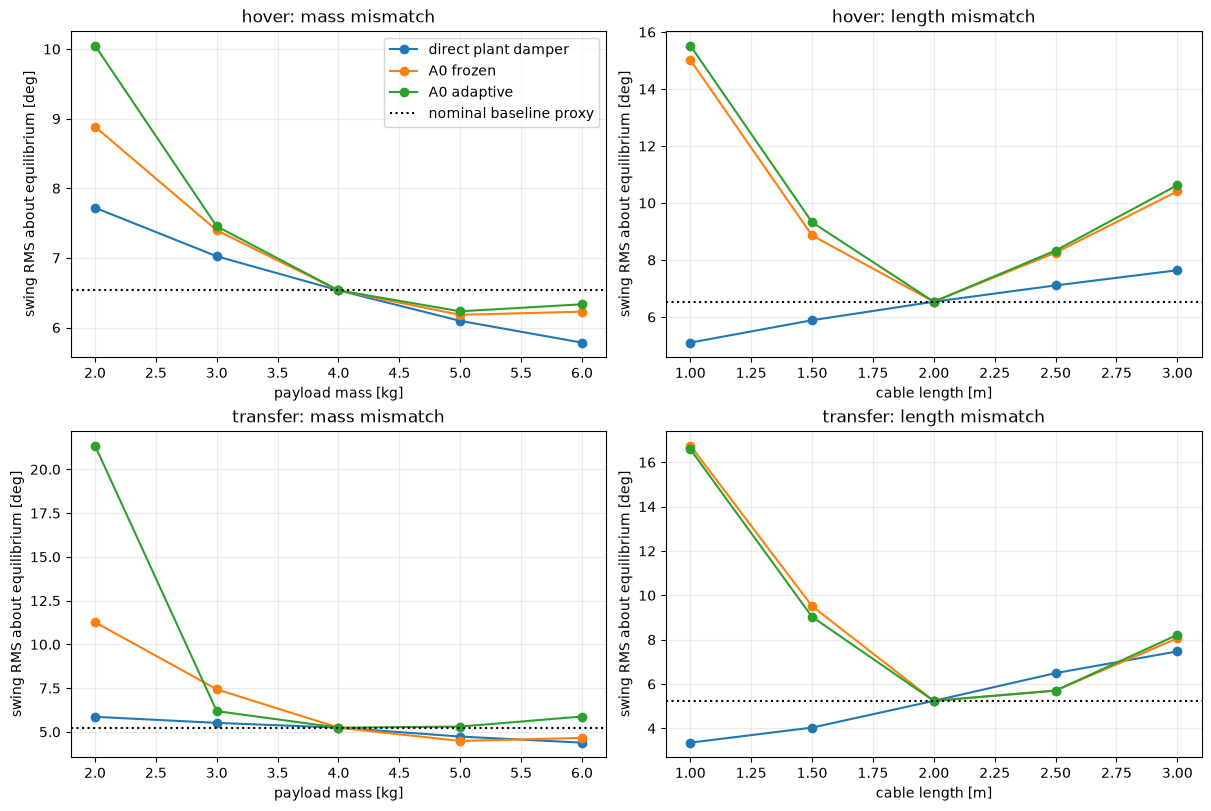

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for row, scenario in enumerate(("hover", "transfer")):
    for col, (family, x, xlabel) in enumerate((
        ("mass", "m_L", "payload mass [kg]"),
        ("length", "L", "cable length [m]"),
    )):
        ax = axes[row, col]
        sub = selected[(selected.scenario == scenario) & (~selected.failed)]
        sub = sub[sub.family.isin((family, "nominal"))]
        for arm in arms:
            part = sub[sub.arm == arm].sort_values(x)
            ax.plot(part[x], part.swing_rms_deg, marker="o", label=labels[arm])
        nominal = sub[(sub.family == "nominal") & (sub.arm == "softer")]
        if len(nominal) != 1:
            raise ValueError(f"Expected one successful nominal baseline for {scenario}")
        ax.axhline(nominal.swing_rms_deg.iloc[0], color="black", linestyle=":",
                   label="nominal baseline proxy")
        ax.set(title=f"{scenario}: {family} mismatch", xlabel=xlabel,
               ylabel="swing RMS about equilibrium [deg]")
        ax.grid(alpha=0.25)
axes[0, 0].legend()
plt.show()

## 5. Optional: actual reference and plant trajectories

The next cell **defines** a comparison function; it does not call it. A call executes three deterministic reduced-model episodes (direct, A0 frozen, A0 adaptive), so it requires prior approval of the exact condition, scenario, compute and outputs. No training or gain tuning is involved. It returns partial trajectories and the failure record if an episode exits. A0 reference traces are read from its own snapshots, not inferred from the plant. Reference and plant motor initialization follows `copy_kinematics`, not the stronger full-state identity fixture.

In [4]:
def run_approved_comparison(m_L, length, scenario):
    from experiments.mrac.baselines import canonical_offline_params, run_episode
    from experiments.mrac.payload_reference import make_a0_system

    if scenario not in grid.SCENARIOS:
        raise ValueError(f"Unknown scenario: {scenario!r}")
    base = canonical_offline_params()
    plant, controller, trajectory, initial, n, canon = grid.build_case(
        base, length, m_L, "softer", scenario, True
    )
    direct = run_episode(plant, controller, trajectory, canon.timing, n, initial)
    results = {"direct": direct}
    for name, online in (("frozen", False), ("online", True)):
        trajectory, initial, n = a0_grid.scenario_setup(canon, scenario)
        system = make_a0_system(
            canon, trajectory, a0_grid.law_params(canon), initial,
            mode="copy_kinematics",
        )
        records, failure = system.loop.run(system.start, n, online, online)
        results[name] = {"records": records, "failure": failure, "requested": n,
                         "dt": canon.timing.T_s}
    return results

def plot_approved_comparison(results):
    import numpy as np

    fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True, constrained_layout=True)
    direct = results["direct"]
    axes[0].plot(direct.t, direct.p[:, 0], label="direct plant")
    axes[1].plot(direct.t, direct.p[:, 1], label="direct plant")
    axes[2].plot(direct.t, np.degrees(direct.phi), label="direct plant")
    print("Direct failure:", direct.failure, "completed:", direct.n_completed,
          "requested:", direct.n_requested)
    for name in ("frozen", "online"):
        run = results[name]
        rec = run["records"]
        print(name, "failure:", run["failure"], "completed:", len(rec),
              "requested:", run["requested"])
        if not rec:
            continue
        t = np.arange(len(rec)) * run["dt"]
        for j in (0, 1):
            axes[j].plot(t, [r.measurement.body.p[j] for r in rec], label=f"A0 {name} plant")
        axes[2].plot(t, np.degrees([r.measurement.phi for r in rec]), label=f"A0 {name} plant")
        if name == "online":
            for j in (0, 1):
                axes[j].plot(t, [r.snapshot.p[j] for r in rec], "--", label="A0 nominal reference")
            axes[2].plot(t, np.degrees([r.snapshot.phi for r in rec]), "--", label="A0 nominal reference")
    axes[0].set_ylabel("y [m]")
    axes[1].set_ylabel("z [m]")
    axes[2].set_ylabel("swing angle [deg]")
    axes[2].set_xlabel("time [s]")
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend()
    return fig

In [5]:
# Historical user exploration: 1 kg / 1 m, short transfer. Output retained.
# No rerun here. New live cases need separate explicit approval.
# plot_approved_comparison(run_approved_comparison(1, 1, "transfer"))

## 6. A residual policy and the reference's swing law

Combining MRAC with a residual policy is planned for evaluation on the Pymunk plant, with no observation adapter (project master plan, item A6; a local planning document). Offline MRAC with the damper reference remains the theory and tuning vehicle. Nothing of that combination has been run. (The earlier text of this section called the linear damper a placeholder for a future learned residual inside this offline reference.)

The present `PayloadPIDReferenceModel` constructs `LinearSwingDamper` explicitly; no PPO policy is plugged in. A combination on the Pymunk plant would need its own specified interface: observation channels and ordering, actor-only inputs, deterministic inference, checkpoint and normalization pairing, action dimensions and scaling, reset and history, timing, clipping and allocation, and reference domain exits. The reference bracket and the residual accounting would have to be derived again for that interface; neither the present conclusions nor the nominal identity transfer automatically.

## 7. Boundaries and next steps

- The cache is exploratory, reduced-model and development-PC proxy evidence. It does not establish stability, robustness across a population, Pymunk equivalence, hardware performance, or PPO/MRAC-RL integration.
- No gain tuning, new episodes, training or saved-result overwrite is performed by running all cells.
- No independent scientific review of the present text exists yet. An independent review of an earlier version of this notebook was CONDITIONAL; the notebook changed afterwards, so that review does not cover the present text and is not an acceptance of it. For a new comparison, separately approve the exact run and preserve failures; assess task tracking, reference tracking and real swing separately.

The cache contains one deterministic run per cell and remains historical. Its loaded file names a clean source commit (section 3), but without per-file hashes or package versions it is not frozen, independently checked evidence; the saved outputs made from earlier generations stay source-unverified (the earlier text gave unavailable identities of uncommitted sources as the reason). Mechanism explanations in this notebook are hypotheses or interpretations, not causal findings established by the cached comparisons.


## 8. Long-horizon diagnostic: the current MRAC law is not accepted

**VERIFIED empirical failure in the approved case.** The earlier short episodes were insufficient. The new saved run uses the unchanged gains and reduced taut model, a real load of 6 kg / 2 m, and a 4 m lateral minimum-jerk transfer over 4 s followed by hold. The nominal loaded reference is 4 kg / 2 m. The user-explored 1 kg / 1 m case above was preserved, not rerun; it is not this diagnostic case.

| Recipe / budget | Value |
|---|---|
| Control / physics step | 0.02 s / 0.002 s, 10 substeps |
| Requested horizon per arm | 120 s |
| CPU workers / total wall cap / extra RAM cap | 1 / 300 s / 2 GiB |
| Actual aggregate wall time / final extra RSS | 36.984 s / 7,065,600 bytes |
| Stops | taut exit, nonfinite values, 10 m task error, 90 degree vehicle tilt |

All five arms were attempted, with failures preserved. ONLINE enables both vehicle and payload adaptation. No tuning, training, estimator, extra damping law, or overwrite of historical results was performed. The cells below **only read saved data**. Source hashes and complete parameters are in the run receipt. The cached A0 grid of sections 3 and 4 is not frozen evidence either: its lineage and limits are in section 3 (the earlier text described it only as computed from a checkout with uncommitted changes). Do not upgrade that cache to reproducible frozen evidence.

| Arm | End / stop time [s] | Outcome |
|---|---:|---|
| Direct softer law | 120.000 | Completed |
| Loaded-reference A0 FROZEN | 24.080 | 10 m task error |
| Loaded-reference A0 ONLINE | 18.100 | 10 m task error |
| No-load-reference FROZEN | 6.532 | Taut-domain exit |
| No-load-reference ONLINE | 5.947 | Taut-domain exit |

**Do not rank whole-episode RMS across truncated failures and the completed baseline.** The loaded references still have small task error at the real-plant stops. Both FROZEN and ONLINE fail, so adaptation is not the sole cause. In A0 FROZEN, filter error exceeds 0.2 rad before motor saturation or requested-thrust domain violation. This ordering is telemetry, not a causal ablation.

*Reading the zoom panels:* each shows the same saved arrays as the full-run panel, limited to the shaded time window, with the vertical range fitted to the data inside that window. Here the window contains the last sample of every failed trace.

In [6]:
import json
DIAG_DIR = Path('results/mrac_long_horizon_20261124T231900')
receipt = json.loads((DIAG_DIR / 'receipt.json').read_text(encoding='utf-8'))
hover_audit = json.loads((DIAG_DIR / 'hover_linearization.json').read_text(encoding='utf-8'))
if receipt['status'] != 'completed':
    raise RuntimeError('Diagnostic receipt is incomplete; inspect preserved files before scoring')
diagnostic_data = {}
rows = []
for arm in receipt['arms']:
    s = receipt['summaries'][arm]
    df = pd.read_csv(DIAG_DIR / f'{arm}.csv')
    if len(df) != s['n_completed']:
        raise ValueError(f'{arm}: CSV count does not match receipt')
    diagnostic_data[arm] = df
    rows.append(dict(arm=arm, completed_ticks=s['n_completed'], requested_ticks=s['n_requested'],
                     stop_time_s=s['stop_time_s'], stop=s['stop']['kind'] if s['stop'] else 'completed',
                     max_requested_thrust_N=s['requested_thrust_max_N'],
                     Q_domain_violating_ticks=s['q_domain_violating_ticks'],
                     saturation_ticks=s['saturation_ticks']))
display(pd.DataFrame(rows))
display(pd.DataFrame([dict(case=k, spectral_radius=v['spectral_radius'],
                          growth_rate_per_s=v['growth_rate_per_s'])
                      for k, v in hover_audit['cases'].items()]))
print('PROXY exploratory evidence. No gain tuning or new episodes in this cell.')


,arm,completed_ticks,requested_ticks,stop_time_s,stop,max_requested_thrust_N,Q_domain_violating_ticks,saturation_ticks
0,direct_softer,6000,6000,120.000,completed,163.144441,0,0
1,a0_frozen,1204,6000,24.080,task_error_10m,537.887107,138,174
2,a0_online,905,6000,18.100,task_error_10m,1978.217186,142,170
3,no_load_frozen,326,6000,6.532,taut_exit,222.971205,24,30
4,no_load_online,297,6000,5.947,taut_exit,440.306823,103,118


,case,spectral_radius,growth_rate_per_s
0,a0_nominal_frozen,1.003002,0.149862
1,a0_ideal_frozen,1.004525,0.225750
2,a0_ideal_online_alpha,1.004377,0.218377
3,no_load_nominal_frozen,1.008352,0.415848
4,no_load_ideal_frozen,1.006723,0.335017


PROXY exploratory evidence. No gain tuning or new episodes in this cell.


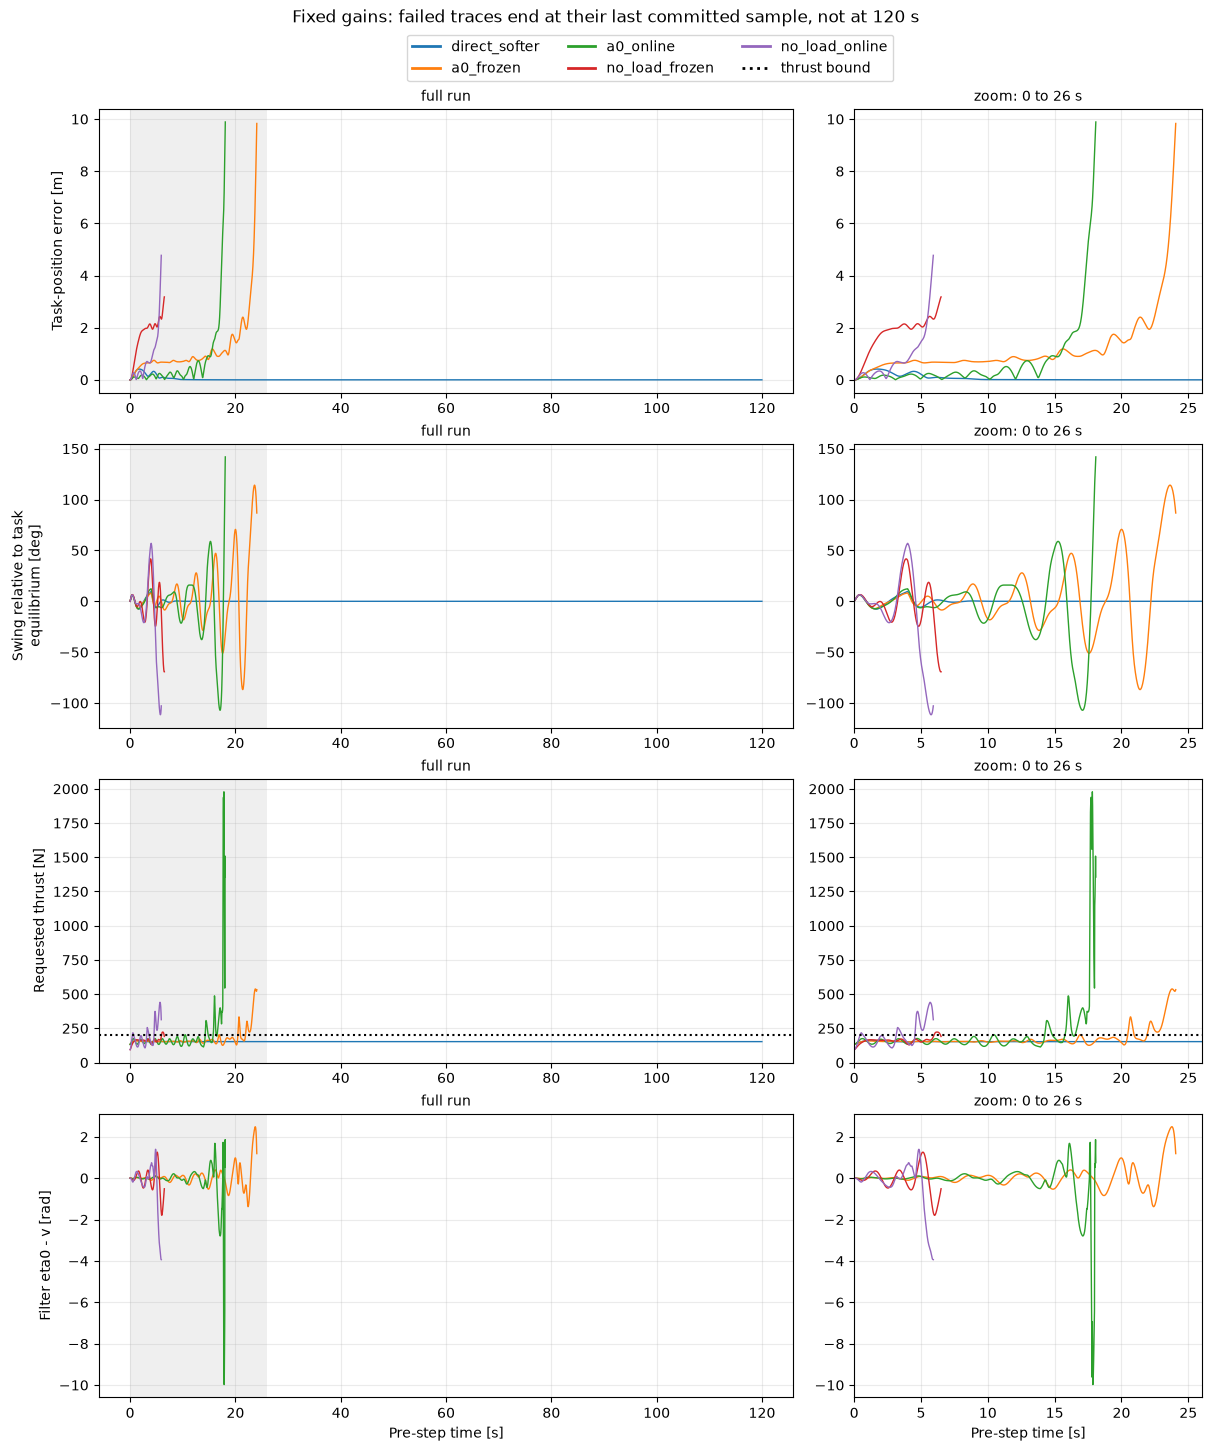

In [7]:
fig = plt.figure(figsize=(12, 14.4), layout='constrained')
gs = fig.add_gridspec(5, 2, height_ratios=[0.14, 1, 1, 1, 1], width_ratios=[2, 1])
legend_ax = fig.add_subplot(gs[0, :]); legend_ax.axis('off')  # own row for the shared legend, so it cannot cover the title or data
axes = [[fig.add_subplot(gs[r + 1, c]) for c in range(2)] for r in range(4)]
ZOOM = (0, 26)  # contains the last sample of every failed trace
panels = [('Task-position error [m]', lambda d: d.task_error_m),
          ('Swing relative to task\nequilibrium [deg]', lambda d: d.swing_rel_rad * 180 / 3.141592653589793),
          ('Requested thrust [N]', lambda d: d.f_req_N),
          ('Filter eta0 - v [rad]', lambda d: d.eta0_minus_v_rad if 'eta0_minus_v_rad' in d else None)]
for row, ((full, zoom), (ylabel, value)) in enumerate(zip(axes, panels)):
    inside = []
    for k, (arm, df) in enumerate(diagnostic_data.items()):
        y = value(df)
        if y is None:
            continue
        for ax in (full, zoom):
            ax.plot(df.t_s, y, label=arm, color=f'C{k}', lw=1.0)  # one colour per arm in every panel
        inside.extend(y[(df.t_s >= ZOOM[0]) & (df.t_s <= ZOOM[1])])
    if row == 2:
        for ax in (full, zoom):
            ax.axhline(2 * receipt['plant']['T_max'], color='black', linestyle=':', label='thrust bound')
    pad = 0.05 * (max(inside) - min(inside))
    zoom.set_xlim(*ZOOM)
    zoom.set_ylim(min(inside) - pad, max(inside) + pad)
    if row:
        full.sharex(axes[0][0])
    full.axvspan(*ZOOM, color='0.5', alpha=0.12, lw=0)
    full.set_ylabel(ylabel)
    full.set_title('full run', fontsize=10)
    zoom.set_title('zoom: %g to %g s' % ZOOM, fontsize=10)
    for ax in (full, zoom):
        ax.grid(alpha=0.25)
for ax in axes[-1]:
    ax.set_xlabel('Pre-step time [s]')
leg_handles, leg_labels = axes[2][0].get_legend_handles_labels()
legend = legend_ax.legend(leg_handles, leg_labels, loc='center', ncol=3, fontsize=10)
for line in legend.get_lines():
    line.set_linewidth(2.0)
fig.suptitle('Fixed gains: failed traces end at their last committed sample, not at 120 s');

### 8.1 Matching conditions, adaptation gains and robustness audit

| Obligation | Result / scope |
|---|---|
| Constant reduced-model parameters and positive effectiveness | Verified for this recipe; symmetric unit effectiveness |
| True force-row ideals inside projection | [9.6, 6, 12]; all inside the existing boxes |
| True torque-row ideals inside projection | [1.5447816, 6, 12], alpha = 0; all inside |
| Reference bracket | Includes the nominal payload; earlier symbolic identity check passed |
| Feedback gains | lambda_p=1.5, lambda_theta=5, k_p=20, k_theta=25, all positive |
| Adaptation gains | Gamma_p=diag(0.05,3,3), Gamma_theta=diag(0.01,0.01,0.01), gamma_alpha=0.0001 |
| Filter | (s+5)^3 is Hurwitz; positivity alone would not certify a generic higher-order polynomial |
| Placeholder Q family | Worst algebraic margin 6.78724, shared c interval (200.28458,249.71542); not a stability margin |
| Requested thrust in Q comparison domain | Violated in all four MRAC arms; allocation clipping does not restore this premise |
| Sample hold, lag, filter/geometry residual bounds | Not established by Q positivity or gain positivity |
| Parameter convergence | Not established; a transfer followed by hover does not establish persistent excitation |
| Robust adaptive modification | No sigma/e modification or dead zone is implemented |
| Disturbance estimator | None; the reduced derivation assumes D_v=0 |

The independent force and torque coefficients are not physically identified masses or lengths. At hover the force mass columns are collinear and the first-moment column has no excitation. A finite full-trajectory Gram may be positive because of the departure from hover, including the failure transient; it is not a uniform persistent-excitation certificate. Box contact bounds estimates, not the plant state. Initial zero payload coefficients in the no-load FROZEN arm sit on an intentional boundary, not evidence of projection clipping.

The physical instantaneous input map has rank two for three generalized coordinates: thrust acts along the body axis and the other channel is torque. The exact generalized-wrench regressor is not full-actuation matching. The attitude cascade, filter, sampling and motor dynamics cannot be dropped when importing the scalar matched model of NB02, the matrix model of NB03, or the canonical SISO MRAC-RL conditions in NB04. NB03's explanatory B dimensions / storage notation need care; NB04's generic claim that negative companion-row entries imply Hurwitz is false in degree three and higher. These tutorial statements are not proofs for this system.

### 8.2 PROPOSED local failure mechanism, EQ-MR-16

> **Where this comes from.**
> * **Source:** registry row EQ-MR-16 (derived under assumptions, PROPOSED), built from the hover linearisation of notebook 05, section 4.6, and the law of notebook 07, section 4.3; code `experiments/mrac/diagnostics.py::hover_lateral_map`.
> * **Prerequisites:** those two sections.
> * **Assumptions:** (1) taut hover, symmetric unit effectiveness; (2) no motor clipping, no angle wrap; (3) reference at rest at hover; (4) the same payload coefficient $m_h$ in the force and torque rows (for this audit only); (5) first-order motor lag on the torque; (6) frozen estimates (the ideal ONLINE variant adds $\hat\alpha$).

Fix the reference at taut hover and take its zero-perturbation subspace, which is invariant because the real plant does not drive the reference. Let f0=(m_q+m_L)g and use unwrapped small-angle perturbations. Linearizing the reduced equations gives
$$m_q\ddot y=-f_0\theta+m_Lg\phi,\quad J\ddot\theta=\tau+dm_Lg(\phi-\theta),$$
$$L\ddot\phi=-(\ddot y+d\ddot\theta+g\phi),\quad \dot\tau=(\tau_c-\tau)/\tau_m.$$
The four equations are, in order: the lateral force balance (thrust tilt and cable pull), the attitude balance with the cable moment, the swing equation, and the motor lag on the torque. The law's side is linearised in three steps.

**Step 1 (vertical equilibrium).** At rest with frozen estimates the vertical thrust the law produces, $g(\hat m_q+\hat m_L)-k_ps_{z0}$, must balance $f_0$ (the calculation of notebook 07, section 10.1a), so at a FROZEN vertical equilibrium $s_{z0}=\big((\hat m_q+\hat m_L)-(m_q+m_L)\big)\,g/k_p$. It is not zero unless the estimated total mass is the true one.

**Step 2 (first-order regressor).** Use $w\approx[\phi,\,-1,\,d(\phi-\theta)]^{\top}$, $\dot w\approx[\dot\phi,\,0,\,d(\dot\phi-\dot\theta)]^{\top}$ and $s=[s_y,\,s_{z0},\,s_\theta]^{\top}$. In the lateral and torque rows: $w\,(w^{\top}\ddot\xi_{\rm ref})$ is of second or higher order; in $-\tfrac12(\dot ww^{\top}+w\dot w^{\top})s$ only $+\tfrac12 s_{z0}\dot w$ survives, because $w^{\top}s\approx-s_{z0}$ and the $w\,(\dot w^{\top}s)$ part is of higher order; and $-g\cos\phi\,w$ gives $-g\phi$ and $-gd(\phi-\theta)$. So
$$Y_{m_L,y}\approx-g\phi+\tfrac12s_{z0}\dot\phi,\qquad Y_{m_L,\theta}\approx-gd(\phi-\theta)+\tfrac12 ds_{z0}(\dot\phi-\dot\theta)\quad\text{(payload-mass column)},$$
$$Y_{m_q,y}=-\lambda_p\dot y,\qquad Y_{J,\theta}=\eta_2-\lambda_\theta(\dot\theta-\eta_1),\qquad Y_\mu\approx0\quad\text{(vehicle columns; }Y_\mu\propto\dot\phi^2).$$

**Step 3 (command).** At the hover reference $b'(\theta_r)=[-1,0]^{\top}$, $B_{r,y}=0$, $B_{r,\theta}=0$, $\tau_r=0$, $s_y=\dot y+\lambda_py$ and $s_\theta=(\dot\theta-\eta_1)+\lambda_\theta(\theta-\eta_0)$. The cascade of notebook 07, section 4.3.4, becomes
$$v_{lin}=-\frac{\hat m_qY_{m_q,y}+m_hY_{m_L,y}-k_ps_y}{f_r}\quad\text{(tilt command; }v=b'^{\top}\Delta F/f_r),$$
$$\tau_{c,lin}=\hat JY_{J,\theta}+m_hY_{m_L,\theta}-k_\theta s_\theta\quad\text{(torque command; the term }\hat\alpha f_c\text{ vanishes for the frozen value }\hat\alpha=0).$$
With the same payload coefficient $m_h$ in both rows (for this specific equilibrium audit), substituting step 2, keeping the first-order $-\tfrac12\dot Ms$ terms and collecting each state gives
$$v_{lin}={k_p\lambda_p y+(\hat m_q\lambda_p+k_p)\dot y+m_hg\phi-\tfrac12m_hs_{z0}\dot\phi\over f_r},$$
$$\tau_{c,lin}=(m_hdg-k_\theta\lambda_\theta)\theta-(\hat J\lambda_\theta+k_\theta+\tfrac12m_hds_{z0})\dot\theta-m_hdg\phi+\tfrac12m_hds_{z0}\dot\phi+k_\theta\lambda_\theta\eta_0+(\hat J\lambda_\theta+k_\theta)\eta_1+\hat J\eta_2.$$
The filter receives held v, the plant receives the command computed from the old eta, and the first-order motor-lag / filter maps are advanced by exact ZOH. The optional ideal ONLINE Jacobian adds -f0 alpha_hat to torque and the existing Euler update T_adapt gamma_alpha f0 s_theta. Generic nonideal ONLINE estimates are not equilibrium points and were not linearized. The symbolic first-order regressor check returned eighteen zero residuals.

**The saved Jacobians have eigenvalue modulus greater than one, including ideal payload coefficients.** This is a derived-under-assumptions local instability mechanism of the idealized sampled lateral cascade, not an independently accepted nonlinear theorem or an extra rollout. It supports investigating the full lateral/swing/filter/actuator loop before increasing adaptation gains. Perfect disturbance estimation is not shown to cure it. The nominal identity fixture tests invariance of an exactly copied trajectory, not transverse stability under mismatch or perturbation.

### 8.3 Disturbance-weight extension: derived cancellation only, NOT IMPLEMENTED

For a declared matched uncertainty, define G(theta) with columns (b(theta),0) and (0,0,1), K=diag(kappa,kappa_tau)>0, known basis psi in R^r, and an unknown constant matrix W_star in R^(r x 2). The physical disturbance is D=G K W_star^T psi + epsilon. Each output column of W_star must have command-equivalent thrust / torque units appropriate to its basis. This excludes an arbitrary world-lateral wind force, which is not instantaneously in the two-channel input span.

If the **derived error equation** contains s^T D, an input cancellation -W_hat^T psi produces -s^T G K W_tilde^T psi, with W_tilde=W_hat-W_star. Choose
$$V_W=\tfrac12\operatorname{tr}(W_{tilde}K W_{tilde}^T\Gamma_W^{-1}),\quad \dot{\hat W}=+\Gamma_W\psi s^TG,\quad \Gamma_W>0.$$
Its storage derivative cancels that cross term algebraically. Dimensions: $s\in\mathbb R^3$, $G\in\mathbb R^{3\times2}$, $K\in\mathbb R^{2\times2}$, $\psi\in\mathbb R^r$, $W\in\mathbb R^{r\times2}$, $\Gamma_W\in\mathbb R^{r\times r}$ symmetric. Steps:
1. The plant adds $D$ and the command subtracts $\hat W^{\top}\psi$, which the motors scale by $K$; apart from $\epsilon$, the error equation therefore contains $s^{\top}GK\big(W_\star^{\top}\psi-\hat W^{\top}\psi\big)=-s^{\top}GK\tilde W^{\top}\psi$.
2. $\dot V_W=\tfrac12\mathrm{tr}(\dot{\hat W}K\tilde W^{\top}\Gamma_W^{-1})+\tfrac12\mathrm{tr}(\tilde WK\dot{\hat W}^{\top}\Gamma_W^{-1})=\mathrm{tr}(\tilde WK\dot{\hat W}^{\top}\Gamma_W^{-1})$ (product rule with $\dot{\tilde W}=\dot{\hat W}$ for constant $W_\star$; the two traces are equal by transposition and the cyclic property, using that $K$ (diagonal) and $\Gamma_W$ are symmetric).
3. With $\dot{\hat W}^{\top}=G^{\top}s\,\psi^{\top}\Gamma_W$: $\dot V_W=\mathrm{tr}(\tilde WKG^{\top}s\,\psi^{\top})=\psi^{\top}\tilde WKG^{\top}s=s^{\top}GK\tilde W^{\top}\psi$ (cyclic property; a scalar equals its transpose), which is the negative of the term in step 1.

The positive sign follows from subtracting the estimate in the command. epsilon remains an approximation/unmatched residual. This conditional cancellation is not a stability proof for the present unstable cascade. The unknown asymmetry coupling, placement relative to f_c/v/alpha, projection metric, basis boundedness, residual envelope, sampling and saturation all require a new integrated derivation. Overlapping constant/gravity bases and mass regressors also prevent automatic identifiability.

**No basis, estimator gains or robust modification were selected or implemented.** A constant body-thrust/torque bias basis would not be a general wind estimator. Gain tuning remains NOT RUN. New estimator or stabilizing-law work needs a scoped scientific decision and independent review. The present notebooks now expose failure rather than claiming the existing MRAC law is fixed.

## 9. Root causes of the long-horizon instability and a structural modification (EQ-MR-18, PROPOSED)

Section 8 showed that both the loaded-reference (A0) and the no-load-reference MRAC fail at 6 kg / 2 m over 120 s, with FROZEN and with ONLINE estimates. This section identifies **three** mechanisms and implements an **opt-in** structural modification for two of them. No feedback or adaptation gain was changed (`k_p`, `k_theta`, `lambda_p`, `lambda_theta`, every `gamma`). The tilt-filter bandwidth was set by the stated loop-shaping rule in 9.1, not selected by episode performance. The legacy law (`swing_regressor="measured"`, filter `(s+5)^3`) remains the default. Independent scientific review: `.ai/work/2026-11-25-mrac-stabilized-review/review.md` (corrections of 2026-11-25 applied here).

### 9.1 C1: the outer lateral loop has negative phase margin

> **Where this comes from.**
> * **Source:** registry row EQ-MR-18 and the stabilization review named above; code `experiments/mrac/diagnostics.py`.
> * **Prerequisites:** section 8.2 (the tilt command $v_{lin}$); the phase margin of a feedback loop.
> * **Assumptions:** (1) ideal attitude, $\theta=\eta_0$ and $\theta_r=0$; (2) no sampling and no motor lag; (3) no payload ($m_L=m_h=0$) and $\hat m_q=m_q=m$; (4) hover, small angles.

The desired tilt passes through the third-order filter `F(s) = a0/(s^3 + a2 s^2 + a1 s + a0)`, with legacy `(s+5)^3`. Assume ideal attitude, no sampling, no motor lag and no payload. The lateral loop is then
$$L(s) = F(s)\,\frac{c_1 s + c_0}{m\,s^2},\qquad c_1 = \hat m_q\lambda_p + k_p,\quad c_0 = k_p\lambda_p .$$
**Steps to this loop.**
$$m\ddot y=-f_r\,\theta\quad\text{(lateral balance at hover thrust }f_r=mg),$$
$$\theta=F(s)\,v\quad\text{(ideal attitude follows the filtered tilt command)},$$
$$v=\frac{(\hat m_q\lambda_p+k_p)\,s+k_p\lambda_p}{f_r}\,y\quad\text{(section 8.2 with }m_h=0),$$
$$ms^2y=-F(s)\,(c_1s+c_0)\,y\ \Longleftrightarrow\ \big(1+L(s)\big)\,y=0\quad\text{(substitute; }f_r\text{ cancels)}.$$

With `k_p = 20`, `lambda_p = 1.5` and `m = m_hat_q = 9.6` kg, `c1 = 34.4` and `c0 = 30`. With $F$ a triple pole at $a$, the phase margin at the gain crossover $\omega_c$ (where $\lvert L(j\omega_c)\rvert=1$) is
$$\mathrm{PM}=\arctan\frac{c_1\omega_c}{c_0}-3\arctan\frac{\omega_c}{a}$$
(lead of the numerator zero minus lag of the three filter poles; the $-180$ deg of $1/s^2$ cancels the $+180$ deg in the definition of the margin). For the legacy $a=5$: $\omega_c\approx2.62$ rad/s, lead 71.6 deg, lag 83.0 deg, so the continuous phase margin is about **-11 deg**. (The earlier text said crossover lies beyond the filter poles; it does not: $\omega_c$ is below $a$. The margin is negative because the three poles already lag more there than the zero leads.) A half-sample delay subtracts $0.01\,\omega_c$ rad; the motor lag subtracts $\arctan(0.05\,\omega_c)$ and also shifts $\omega_c$ slightly.

**Intuition.** The filter delays the tilt that the position loop asks for. Around the frequency where the loop gain is one, that delay is larger than the anticipation provided by the velocity term, so corrections arrive late enough to feed the error.

| Filter pole `a` [rad/s] | 5 (legacy) | 7.5 | 10 | 15 | 20 |
|---|---|---|---|---|---|
| Phase margin, ideal loop [deg] | -11.4 | 8.5 | 21.4 | 37.1 | 46.1 |
| With a half-sample delay (0.01 s) | -12.9 | 6.8 | 19.6 | 35.2 | 44.1 |
| With motor lag `tau_m = 0.05` s and the delay | -20.1 | -1.3 | 10.9 | 25.8 | 34.5 |

Source: `results/mrac_review_checks_20261125/review_checks.json` (R-3). The labels R-1, R-2 and R-3 are the three checks that the stabilization review requested (R-1: finite-difference Jacobian of one real closed-loop tick; R-2: envelope fit of the height error; R-3: numerical check of this phase-margin table and of the sampled vertical rate), listed under "Checks requested from authorized execution" in the local, untracked review record named above. That JSON file holds their saved results; the script that wrote it was not saved (`RESULTS_REGEN.md`). The 45 deg figure is an indicator for the ideal continuous loop. Including motor lag, the margin at `a = 20` is about 34 deg.

**Design rule:** take the smallest `a` in {5, 7.5, 10, 15, 20} whose ideal-loop phase margin is at least 45 deg. That gives `a = 20`, so `filter_a = (8000, 1200, 60)`.
- The rule was fixed before the stabilized episodes. It is recorded in the hashed run source (`diagnostics.py`); there is no earlier log.
- `a = 20` is the largest candidate and clears 45 deg by 1 deg.
- The triple pole is faster than the attitude-error poles, which weakens the ideal-attitude assumption.
- The filter gain `a0` rises from 125 to 8000; noise sensitivity has not been assessed.

### 9.2 C2: what cancelling the measured swing does to the real swing

The payload regressor `Y_mL` was evaluated at the **measured** plant swing `(phi, phi_dot)` and attitude. With ideal payload coefficients, the law's lateral force **request** therefore cancels the first-order lateral cable pull `m_L g phi`. What reaches the plant is the realised linear row below, which in general keeps part of the cable pull. In continuous time the real swing deviation is near-marginal zero dynamics only when that remainder vanishes, `m_h = m_L f_r / f_0` (with ideal coefficients `m_h = m_L` this needs `f_0 = f_r`, which for the A0 reference means the nominal 4 kg payload). With ideal coefficients the remainder is `m_L g (1 - f_0/f_r) phi`; for the no-load reference `f_0/f_r = 1 + m_L/m_q`, that is 1.21, 1.42 and 1.63 at 2, 4 and 6 kg (over-cancellation). (An earlier text called the real swing near-marginal without this condition.) In the sampled maps its sign is set by the cancellation residual:
- over-cancellation (nominal 4 kg on a 2 kg load) is anti-damping;
- under-cancellation is damped;
- exact cancellation is near-marginal.

**The linear row.** Take section 8.2 with ideal tilt at low frequency ($\theta=v_{lin}$) and substitute into $m_q\ddot y=-f_0\theta+m_Lg\phi$ (elementary substitution):
$$m_q\ddot y=-\frac{f_0}{f_r}\big[k_p\lambda_py+(\hat m_q\lambda_p+k_p)\dot y\big]+\Big(m_L-\frac{f_0}{f_r}m_h\Big)g\,\phi+\frac{f_0}{f_r}\,\frac{m_h}{2}\,s_{z0}\,\dot\phi .$$
The coefficient of $\phi$ is what remains of the cable pull. It is positive for under-cancellation, negative for over-cancellation, and zero when $m_h=m_Lf_r/f_0$; since $f_r$ is the reference thrust (A0: $(m_{q,r}+m_{L,r})g$; no-load: $m_{q,r}g$), ideal coefficients $m_h=m_L$ give zero only if $f_0=f_r$.

This is the open design question labelled "R6" in the local, untracked tuning notes (`.ai/work/2026-11-24-mrac-tuning/README.md`): in A0 the swing-mismatch equation has no direct damping term, so the **real** swing has no designed damping; the damper acts only inside the reference, and active damping of the real load would be a separate law variant.

**Modification:** evaluate the regressor at the **reference** swing and attitude, `Y = Y(theta_r, omega_r, phi_r, phi_dot_r, xi_ddot_ref, s)`, in both the command **and the adaptation update**.
- In A0 the reference swing is the nominal loaded pendulum, which is damped by the softer law.
- In the no-load reference, `phi_r = atan2(-p_ddot_r,y, g + p_ddot_r,z)` (the quasi-static equilibrium) with `phi_dot_r = 0`.

The law then feeds forward the cable force the *reference* expects (in the linear row above, the $\phi$ and $\dot\phi$ terms of the command then use the reference swing, at rest at hover, so the full pull $m_Lg\phi$ remains). The deviation coupling is no longer cancelled, so the real cable couples the swing to the vehicle feedback. In the hover linearizations this damps it, lightly.
- This damping is passive and not a design parameter. It comes from tracking error, so tighter tracking reduces it.
- It is weaker than, and not equivalent to, the "swing-error shaper" proposed as option R3 in a meeting brief saved with the stabilization review (local, untracked: `.ai/work/2026-11-25-mrac-stabilized-review/snapshot/meeting_brief.md`). That proposal keeps the exact cancellation and adds a designed damper on $\phi-\phi_r$ through a target offset $\Delta p$, with $\Delta\ddot p=k_dl_n(\dot\phi-\dot\phi_r)\,t(\phi)-k_1\Delta p-k_2\Delta\dot p$ ($k_d,k_1,k_2$ its design gains, $l_n$ the nominal length). It is not implemented. (The tuning notes use the label R3 for a different item.)
- Combining R3 with the reference regressor would need an interconnection argument.

**Matching consequence (stated, not hidden):** the term `(Y(x) - Y(x_r)) Theta*` is no longer compensated and stays in the `s`-dynamics.
- It lies in the input rows, but it vanishes only when the swing and attitude deviations vanish.
- Stability needs an interconnection argument (small-gain or composite Lyapunov) with the swing-deviation dynamics, or UUB under persistent mismatch. **None is proved.**
- The adaptation update also uses `Y(x_r)`, so this residual drives the estimates too, and parameter drift is possible.

### 9.3 Evidence: hover maps, a finite-difference check on the real code, and approved 120 s episodes

| Check | Result |
|---|---|
| R-1: finite-difference Jacobian of one real closed-loop tick vs `hover_lateral_map`. A0 FROZEN, 6 kg / 2 m, nominal 4 kg coefficients, 10 lateral states, after a 400-tick vertical settle | Legacy: FD +0.14986 / s, analytic +0.14986 / s. Stabilized: FD -0.32967 / s, analytic -0.32967 / s. Largest entry difference is 1.0e-5 (largest entry is 41 to 86). Artifact: `results/mrac_review_checks_20261125/review_checks.json` |
| Hover grid: `m_L` in {2, 4, 6} kg, `L` in {1.5, 2, 2.5} m, A0 or no-load reference, nominal or ideal coefficients | 36 map evaluations. In reference mode, nominal and ideal coefficients give the same map, so there are **18 distinct maps**. Table below (cell output) |
| Approved 120 s episodes (Javier, 2026-11-24, core_plus) | **8 episodes on 3 plants**: 4 arms at 6 kg / 2 m, plus the 2 A0 arms at each of (2 kg, 1.5 m) and (6 kg, 2.5 m). Table below |

The earlier figures in this row ("+0.154 and +0.226 / s, 13 states") had no saved artifact and are withdrawn; R-1 replaces them.

**For A0 at 6 kg / 2 m and on the hover grid, both changes are needed:**
- The filter alone leaves 17 of 36 hover maps growing, and the A0 ONLINE episode hits a taut exit at 32 s.
- The reference regressor alone leaves 36 of 36 growing and fails at 31 s and 60 s.
- No-load ablations were not run.

The stabilized variant has 0 of 18 distinct maps growing. The slowest decay is -0.082 / s (no-load reference, 2 kg, 2.5 m) and -0.137 / s for the A0 cases, which is light damping. Per-mode damping has not been reported.

### 9.4 C3: a vertical lumped-mass adaptive mode remains (NOT fixed by EQ-MR-18)

At hover (`phi = 0`) the `m_q` and `m_L` force columns are identical, `g + p_ddot_r,z - lambda_p e_dot_z`. So only the lumped mass `M_hat = m_q,hat + m_L,hat` is adapted, with effective gain `gamma_q + gamma_L = 0.05 + 3 = 3.05`. Linearizing gives
$$M\dot s = -k_p s + g\tilde M,\qquad \dot{\tilde M} = -(\gamma_q+\gamma_L)\,g\,s .$$
Steps ($\kappa=1$, reference at rest, no lag, continuous time):
1. $f_c=\hat M(g-\lambda_p\dot z)-k_ps$ with $s=\dot z+\lambda_pz$ (both mass columns equal $g-\lambda_p\dot z$ here), and $M\ddot z=f_c-Mg$.
2. Write $\hat M=M+\tilde M$ and drop the product $\tilde M\dot z$ (second order): $M(\ddot z+\lambda_p\dot z)=-k_ps+g\tilde M$, which is the first equation since $\dot s=\ddot z+\lambda_p\dot z$.
3. Add the two updates $\dot{\hat m}_q=-\gamma_qgs$ and $\dot{\hat m}_L=-\gamma_Lgs$: the second equation, with $\dot{\tilde M}=\dot{\hat M}$.
4. The characteristic polynomial is $x^2+(k_p/M)\,x+(\gamma_q+\gamma_L)g^2/M=0$, so $\omega_n=g\sqrt{(\gamma_q+\gamma_L)/M}$ and $\zeta=k_p/(2M\omega_n)$.

At `M = 15.6` kg this loop is lightly damped in continuous time: `zeta = 0.15`, `omega_n = 4.3` rad/s.

**Intuition.** The estimate acts as an integrator on the weight error, and the proportional action on $s$ is the only damping of that integrator.

Adding the motor lag (`tau_m = 0.05` s), the ZOH and the update-after-command order makes the sampled mode **grow slightly**, at +0.005 / s with a 1.38 s period. At 2 kg (`M = 11.6` kg) the sampled rate is +0.031 / s.

**In the 120 s episodes (R-2, envelope fit of `max|z - z_ref|` over 1.38 s windows from 30 s):**

| ONLINE CSV | Envelope rate [1/s] | `m_L,hat` range | Bound ticks |
|---|---|---|---|
| core A0, 6 kg / 2 m | +0.0062 | 2.16 to 10 | 10 from 118.18 s (3 ticks) |
| core no-load | +0.0007 | 0 to 10 | 10 from 0.54 s (124 ticks); starts at 0 |
| grid A0, 2 kg / 1.5 m | +0.0006 | 0 to 4.42 | 0 from 4.16 s (294 ticks) |
| grid A0, 6 kg / 2.5 m | +0.0019 | 2.05 to 10 | 10 from 61.56 s (86 ticks) |

- `m_L,hat` reaches one projection bound per episode; no episode reaches both (core no-load starts at 0, the initial value).
- Over 120 s the slow growth limited the mode. Over longer horizons the linear analysis predicts that only projection would bound it.
- **Thrust headroom is small.** In core A0 ONLINE the requested thrust peaks at 198.1 N against a 201.0 N limit. `no_load_online` has 19 saturation ticks and 13 ticks outside the Q domain.
- "Completed" therefore does not mean "acceptable".
- Additions examined afterwards: σ-modification (EQ-MR-19), the bias estimator (EQ-MR-20) and wind (EQ-MR-21), in section 10 (the earlier text said that section was still to be added).

FROZEN arms show a different, expected effect: a constant altitude offset `Delta M g/(k_p lambda_p)` (derived in notebook 07, section 10.1a). That is 0.654 m for a 2 kg mismatch and 1.962 m for 6 kg against the no-load reference, and it matches `task_rms_90_120s_m` in every relevant receipt. The legacy law has no integral or bias action.

### 9.5 Disturbance estimator: which basis is safe

The candidate of section 8.3 (EQ-MR-17), `D = G K W_star^T psi`, subtracts `W_hat^T psi` and updates `W_hat_dot = +Gamma_W psi s^T G`. The basis choice is now constrained by C2 and C3:
- A basis containing **real swing deviations** (`phi - phi_r`, `phi_dot`) would, at its ideal weights, reproduce the ideal-coefficient `filter_only` maps (13 of 18 growing). Such a basis must not be used.
- A **constant bias** basis `psi = [1]` per input channel would remove the FROZEN offset. It overlaps the comparator that an earlier tuning protocol proposed under its decision label "D5": a frozen-estimate arm with an added force-bias integrator driven by $s_p$ (local, untracked: `.ai/work/2026-11-24-mrac-tuning/01_tuning_protocol.md`; that protocol was never frozen and is superseded, although the earlier text called it pending).
- In the thrust channel it is collinear with the `M_hat` columns at hover. In the vertical scan, a larger effective gain moved the mode from -0.66 / s (`gamma = 0.5`) to +0.005 / s (`gamma = 3.05`). So a bias estimator is expected to **worsen** C3 unless it is analysed jointly with it.
- σ-modification on `M_hat` reintroduces a steady offset.

Implemented as an ablation after this review (EQ-MR-20). The linear prediction from `hover_vertical_rate` (written before the scope A run, but with no tracked timestamp) for bias without σ is a growing vertical mode, worst +0.074 / s on the grid. Scope A did not confirm it (section 10).

### 9.6 Claim limits

All results are reduced-model, development-PC PROXY, EXPLORATORY evidence. Hover maps are local linear evidence. The 8 episodes of 120 s on 3 plants are not a population or a proof. The stabilized variant is PROPOSED: it has been reviewed (CONDITIONAL after corrections), but it is not accepted or frozen. The cells below only **read saved results**.

*Reading the zoom panels:* each shows the same saved arrays as the full-run panel, limited to the shaded time window, with the vertical range fitted to the data inside that window. In the position-error and height rows the large FROZEN offsets set the range, so the ONLINE oscillation looks small there.

In [8]:
import json
from pathlib import Path
RES = Path('results')
analysis = json.loads((RES / 'mrac_stabilized_analysis_20261124' / 'analysis.json').read_text(encoding='utf-8'))
display(pd.DataFrame([dict(variant=v, growing_maps=f"{r['n_growing']}/{r['n_maps']}",
                           worst_growth_rate_per_s=round(r['worst_growth_rate_per_s'], 3))
                      for v, r in analysis['hover_grid'].items()]))
runs = {'stabilized': ['mrac_stabilized_core_20261124T230930', 'mrac_stabilized_grid_20261124T230930'],
        'filter_only': ['mrac_ablation_filter_only_20261124T230930'],
        'regressor_only': ['mrac_ablation_regressor_only_20261124T230930'],
        'legacy': ['mrac_long_horizon_20261124T231900']}
rows, stab_data = [], {}
for variant, dirs in runs.items():
    for name in dirs:
        rec = json.loads((RES / name / 'receipt.json').read_text(encoding='utf-8'))
        if rec['status'] != 'completed':
            raise RuntimeError(f'{name}: incomplete receipt')
        for arm, s in rec['summaries'].items():
            if variant == 'stabilized':
                stab_data[arm] = pd.read_csv(RES / name / f'{arm}.csv')
            rows.append(dict(variant=variant, arm=arm,
                             stop=s['stop']['kind'] if s['stop'] else 'completed',
                             stop_time_s=s['stop_time_s'],
                             task_rms_90_120s_m=s['task_rms_90_120s_m'],
                             swing_rms_90_120s_rad=s['swing_rms_90_120s_rad'],
                             saturation_ticks=s['saturation_ticks'],
                             Q_domain_violating_ticks=s['q_domain_violating_ticks']))
display(pd.DataFrame(rows))
display(pd.DataFrame(analysis['vertical_mode']['scan']))
print('Saved evidence only (PROXY, EXPLORATORY). No episodes, tuning or estimator run in this cell.')

,variant,growing_maps,worst_growth_rate_per_s
0,legacy,36/36,0.434
1,filter_only,17/36,0.231
2,regressor_only,36/36,0.434
3,stabilized,0/36,-0.082


,variant,arm,stop,stop_time_s,task_rms_90_120s_m,swing_rms_90_120s_rad,saturation_ticks,Q_domain_violating_ticks
0,stabilized,a0_frozen,completed,120.000,6.540000e-01,1.045355e-14,0,0
1,stabilized,a0_online,completed,120.000,8.366515e-02,8.676439e-11,0,0
2,stabilized,no_load_frozen,completed,120.000,1.962000e+00,4.090560e-09,0,0
3,stabilized,no_load_online,completed,120.000,9.422880e-02,2.307750e-08,19,13
4,stabilized,a0_frozen_mL2_L1.5,completed,120.000,6.540000e-01,2.460181e-12,0,0
5,stabilized,a0_online_mL2_L1.5,completed,120.000,5.181508e-02,3.389373e-08,0,0
6,stabilized,a0_frozen_mL6_L2.5,completed,120.000,6.540000e-01,3.217336e-11,0,0
7,stabilized,a0_online_mL6_L2.5,completed,120.000,9.163959e-02,1.032189e-10,0,0
8,filter_only,a0_frozen,completed,120.000,6.540002e-01,5.228066e-04,0,0
9,filter_only,a0_online,taut_exit,32.055,NaN,NaN,132,64


,gamma_sum,growth_rate_per_s,period_s
0,0.05,-0.323362,NaN
1,0.50,-0.661409,3.599857
2,1.00,-0.532159,2.409711
3,2.00,-0.259100,1.688476
4,3.05,0.005125,1.381923


Saved evidence only (PROXY, EXPLORATORY). No episodes, tuning or estimator run in this cell.


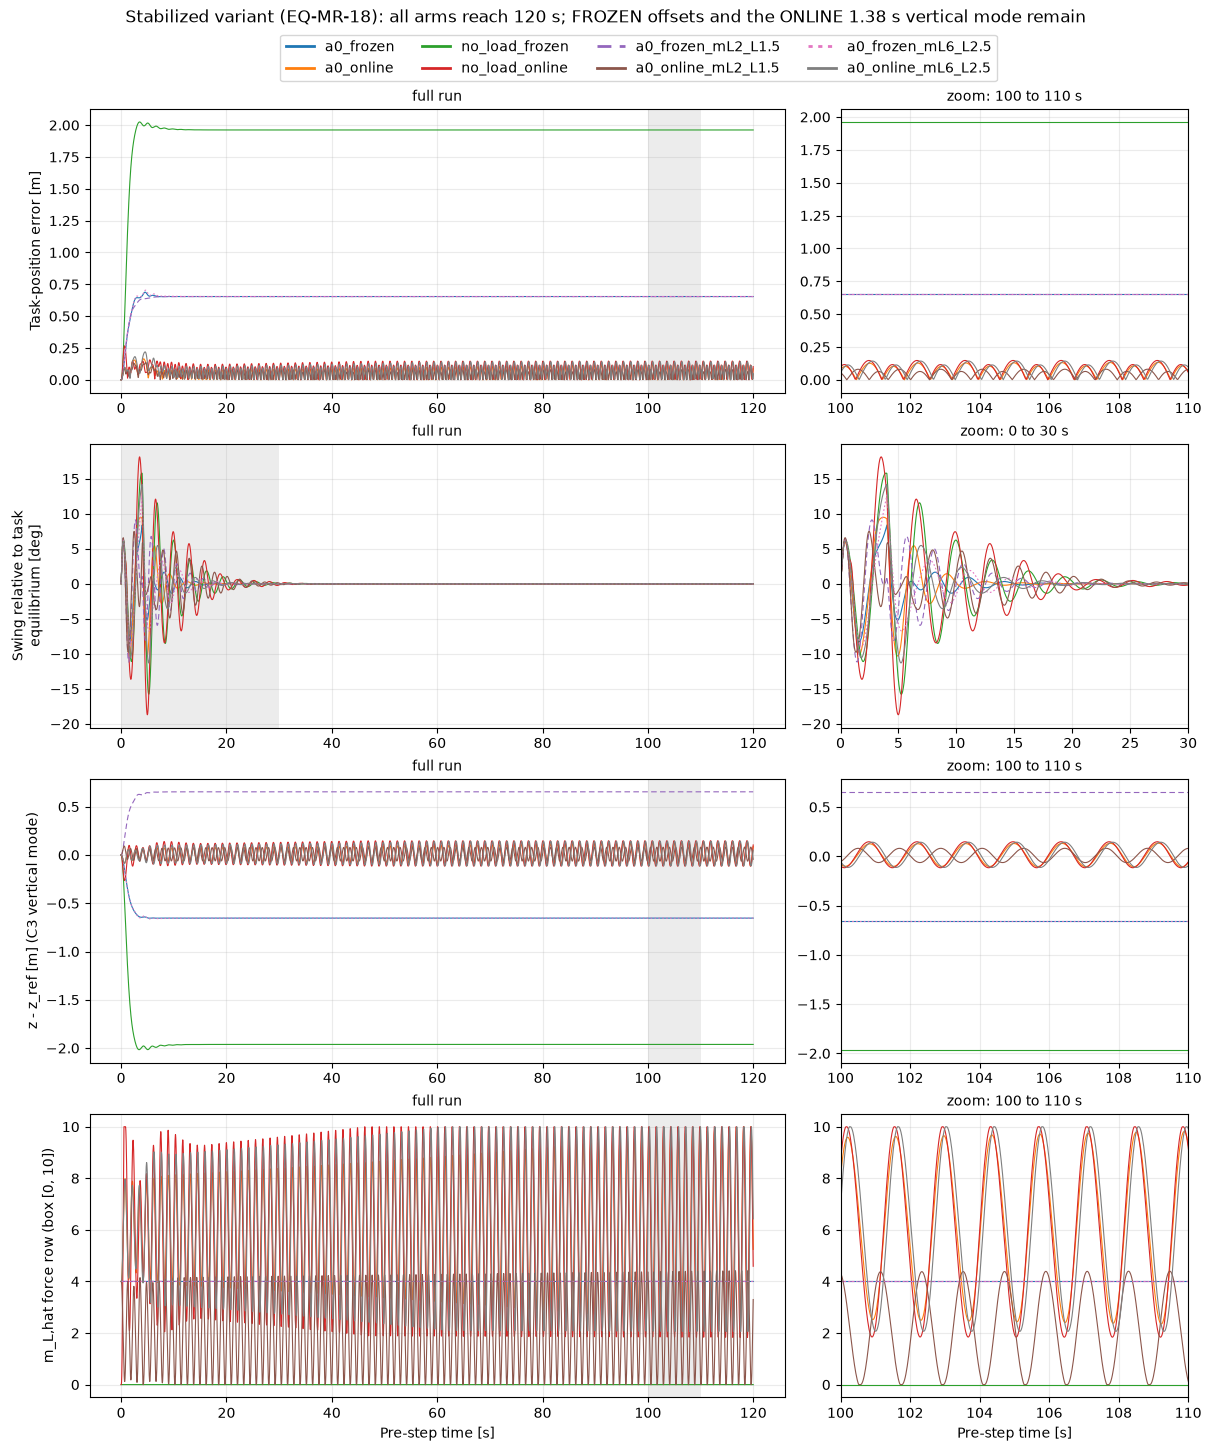

In [9]:
fig = plt.figure(figsize=(12, 14.4), layout='constrained')
gs = fig.add_gridspec(5, 2, height_ratios=[0.14, 1, 1, 1, 1], width_ratios=[2, 1])
legend_ax = fig.add_subplot(gs[0, :]); legend_ax.axis('off')  # own row for the shared legend, so it cannot cover the title or data
axes = [[fig.add_subplot(gs[r + 1, c]) for c in range(2)] for r in range(4)]
panels = [('Task-position error [m]', lambda d: d.task_error_m, (100, 110)),
          ('Swing relative to task\nequilibrium [deg]', lambda d: d.swing_rel_rad * 180 / 3.141592653589793, (0, 30)),
          ('z - z_ref [m] (C3 vertical mode)', lambda d: d.z_m - d.reference_z_m, (100, 110)),
          ('m_L,hat force row (box [0, 10])', lambda d: d.estimate_mL_p, (100, 110))]
# dashed and dotted styles keep coincident FROZEN traces visible
dashes = {'a0_frozen_mL2_L1.5': (0, (5, 3)), 'a0_frozen_mL6_L2.5': (0, (1.5, 2))}
for row, ((full, zoom), (ylabel, value, (lo, hi))) in enumerate(zip(axes, panels)):
    inside = []
    for k, (arm, df) in enumerate(stab_data.items()):
        y = value(df)
        for ax in (full, zoom):
            ax.plot(df.t_s, y, label=arm, color=f'C{k}', lw=0.8, linestyle=dashes.get(arm, '-'))
        inside.extend(y[(df.t_s >= lo) & (df.t_s <= hi)])
    pad = 0.05 * (max(inside) - min(inside))
    zoom.set_xlim(lo, hi)
    zoom.set_ylim(min(inside) - pad, max(inside) + pad)
    if row:
        full.sharex(axes[0][0])
    full.axvspan(lo, hi, color='0.5', alpha=0.15, lw=0)
    full.set_ylabel(ylabel)
    full.set_title('full run', fontsize=10)
    zoom.set_title('zoom: %g to %g s' % (lo, hi), fontsize=10)
    for ax in (full, zoom):
        ax.grid(alpha=0.25)
for ax in axes[-1]:
    ax.set_xlabel('Pre-step time [s]')
leg_handles, leg_labels = axes[0][0].get_legend_handles_labels()
legend = legend_ax.legend(leg_handles, leg_labels, loc='center', ncol=4, fontsize=10)
for line in legend.get_lines():
    line.set_linewidth(2.0)
fig.suptitle('Stabilized variant (EQ-MR-18): all arms reach 120 s; FROZEN offsets and the ONLINE 1.38 s vertical mode remain');

## 10. σ-modification, input-bias ablation and OU wind (EQ-MR-19 to 21, PROPOSED)

The run was approved by Javier on 2026-11-25 as scope A: 34 episodes of 120 s, 6 kg / 2 m, 1 worker, a 60 min aggregate cap (actual 945 s), and `sim_dt = 0.002`, `T_s = 0.02`.
- **Variants:** all are on top of the stabilized law (EQ-MR-18):
  - `+σ`, σ = 0.5 /s, chosen by the ladder rule;
  - `+bias`, Γ_d = (13.08, 13.08, 206.42), chosen by the rule `k²/(4ζ²M)`;
  - `+σ+bias`.
- **Wind (OU, vehicle only):** μ = (5 N, −3 N, 0.5 N·m), σ = (2, 1, 0.2), τ_c = 3 s, seeds 1 to 3. The law and the reference never read it.
- **Gains:** σ and Γ_d are set by the stated rules (EQ-MR-19/20); no other gain changed.

### 10.1 The three additions, derived

> **Where this comes from.**
> * **Source:** registry rows EQ-MR-19 to 21; code `PayloadLaw.advance`, `diagnostics.py::sigma_rule`, `::bias_gain_rule`, `::hover_vertical_rate`, `experiments/mrac/wind.py`.
> * **Prerequisites:** section 9.4; notebook 07, sections 5.1a and 10.1a.
> * **Assumptions:** for the offset and the gain rules: hover, vertical or single-channel linear model, constant coefficients, no active projection.

**Shifted leakage (σ).** The update is $\hat\theta[k+1]=\Pi\big(\hat\theta[k]-T\Gamma Y^{\top}s-T\sigma(\hat\theta[k]-\hat\theta_0)\big)$, with $\hat\theta_0$ the law's nominal estimate. Ioannou and Sun's fixed σ-modification (8.4.11, PDF pp.571-572) leaks toward 0; leakage toward a prior estimate is their "shifted leakage" (Remark 8.4.1(ii), PDF p.578), whose analysis the book leaves to the reader. No bound is claimed here for this sampled law.

**Predicted steady offset.** At a rest point of the vertical loop with $M_0$ the nominal total mass and $\Gamma=\gamma_q+\gamma_L$:
$$k_ps=g\,(\hat M-M)\quad\text{(force balance, section 9.4 with }\dot s=0),$$
$$\Gamma gs+\sigma(\hat M-M_0)=0\quad\text{(estimate at rest: the two updates added)},$$
$$\hat M=\frac{\sigma M_0+aM}{\sigma+a},\qquad a=\frac{\Gamma g^2}{k_p}\quad\text{(insert the first line into the second)},$$
$$e_z=\frac{s}{\lambda_p}=-\frac{g\,\sigma\,(M-M_0)}{k_p\lambda_p\,(\sigma+a)}\quad\text{(at rest }s=\lambda_pe_z).$$
With $\Gamma=3.05$ ($a\approx14.7\ \mathrm{s^{-1}}$) and $\sigma=0.5\ \mathrm{s^{-1}}$: $e_z\approx-0.022$ m for $M-M_0=2$ kg (A0 reference, 6 kg load) and $-0.065$ m for 6 kg (no-load reference).

**σ rule.** The smallest σ in $\{0.05,\,0.1,\,0.2,\,0.5,\,1.0\}\ \mathrm{s^{-1}}$ for which the sampled hover vertical map (thrust lag, exact zero-order hold, command computed before the update) decays at a rate of at most $-0.10\ \mathrm{s^{-1}}$ for every grid lumped mass (11.6, 13.6, 15.6 kg). The result is $\sigma=0.5$.

**Input bias.** The command uses $\Delta F-(\hat d_y,\hat d_z)$ and $\Delta\tau-\hat d_\tau$. For a constant true bias $d$ and $\tilde d=\hat d-d$, the error equation gains $-\tilde d$, and the storage term $\tfrac12\tilde d^{\top}\Gamma_d^{-1}\tilde d$ cancels $-s^{\top}\tilde d$ if $\dot{\hat d}=+\Gamma_ds$. Sampled: $\hat d[k+1]=\Pi\big(\hat d[k]+T\Gamma_ds-T\sigma\hat d[k]\big)$; the leak, present only with σ, is toward 0.

**Gain rule.** One channel, other coefficients frozen, no leak: $M\dot s=-ks-\tilde d$ and $\dot{\tilde d}=\Gamma_ds$, so $M\ddot s+k\dot s+\Gamma_ds=0$. Matching $2\zeta\sqrt{\Gamma_d/M}=k/M$ gives $\Gamma_d=k^2/(4\zeta^2M)$. With $\zeta=0.7$: force channels $k=k_p=20$, $M=15.6$ kg give 13.08; the torque channel $k=k_\theta=25$, $J=1.545\ \mathrm{kg\,m^2}$ in place of $M$ gives 206.42.

**OU wind.** The process $dw=-(w-\mu)\,dt/\tau_c+\sigma_w\sqrt{2/\tau_c}\,dW$ is sampled exactly: $w[k+1]=\mu+(w[k]-\mu)\,e^{-T/\tau_c}+\sigma_w\sqrt{1-e^{-2T/\tau_c}}\,\xi_k$. The first factor is the decay of the mean; the noise variance is $\int_0^Te^{-2(T-u)/\tau_c}\,(2\sigma_w^2/\tau_c)\,du=\sigma_w^2\big(1-e^{-2T/\tau_c}\big)$, so the stationary standard deviation is $\sigma_w$. This $\sigma_w$ is not the leakage σ.

**Intuition.** The leak keeps an estimate that the data no longer inform from wandering, and pays for it with a pull toward the nominal value; the bias states absorb a constant push; the wind model supplies a slowly varying push to test them.

**Linear predictions from `hover_vertical_rate`** (same source hash as the run; sampled hover model at M = 15.6 kg; no timestamped record predates the run) against the rollouts. The observed rate is `ln(std 90-120 s / std 30-60 s)/60` of the lumped estimate M̂, no wind:

| Variant | Predicted (/s) | A0 observed (/s) | No-load observed (/s) | Agreement |
|---|---|---|---|---|
| stabilized | +0.005 | +0.006 | +0.001 | yes (C3 persists; M̂ std 2.6 kg in 90-120 s) |
| +σ | −0.223 | −0.219 | −0.212 | yes |
| +bias | +0.038 | −0.022 | −0.025 | **no** (see below) |
| +σ+bias | −0.189 | −0.181 | −0.166 | yes |

`+bias` without σ does not show the predicted linear growth. M̂ oscillates early (peak 19.73 kg at 48.1 s, A0), and M̂ with d̂_Fz drifts along the unidentifiable collinear direction (d̂_Fz → +14 N, m̂_L,p → 7.8 kg; 60 projection-bound ticks; no saturation). The oscillation then decays slowly (fitted −0.022 /s; M̂ std 0.59 kg in 90-120 s). The linear prediction is therefore not confirmed. The cause is not established, and this is not evidence of stability.

**A0 reference, ONLINE**: the no-wind column is 1 episode; the OU columns are the mean of 3 seeds, and saturation is the max over the seeds.

| Variant | Task RMS 90-120 s (m), no wind | Task RMS 90-120 s (m), OU | Mean e_y 90-120 (m), OU | Mean e_z 90-120 (m), OU | M̂ std 90-120 (kg), OU | Saturation ticks, OU |
|---|---|---|---|---|---|---|
| stabilized | 0.084 | 0.128 | +0.121 | +0.000 | 0.61 | 0 |
| +σ | 0.022 | 0.132 | +0.124 | −0.025 | 0.12 | 0 |
| +bias | 0.019 | 0.029 | −0.002 | +0.000 | 0.45 | 4 |
| +σ+bias | 0.021 | 0.062 | +0.052 | −0.024 | 0.12 | 0 |

**Reading**: EXPLORATORY, PROXY, one plant condition, 3 wind seeds, no stability claim.
- **σ alone:**
  - It suppresses the C3 growth in the hover model and in these 120 s rollouts (one plant).
  - It leaves the predicted vertical offset, |e_z| = 0.022 m at σ = 0.5: the no-wind task RMS in 90-120 s is 0.0215 m with M̂ steady. Under OU wind the mean e_z is −0.025 m (vehicle below the reference), which includes the −3 N mean wind.
  - It does nothing for the lateral wind offset of 0.12 m, because the law has no lateral integral or bias action.
- **The bias estimator:**
  - It removes the mean wind offset (|e_y| ≤ 0.002 m; 3 seeds, one condition).
  - Without σ it keeps the collinear M̂/d̂_Fz drift.
  - With σ, the leak on d̂ leaves half of the lateral offset (0.052 m). At σ = 0.5 the leak competes with Γ_d.
- **Swing RMS** in 90-120 s under wind is about 0.010 rad in all four variants. The real swing gets no designed damping (EQ-MR-18 limits).
- **No-load reference:** see NB07 §13. There, `+bias` raises saturation to 105 to 149 ticks.

No variant is selected here; selection needs a protocol.

In [10]:
import json
from pathlib import Path
import pandas as pd

rows = json.loads(Path("results/mrac_scopeA_sigma_bias_wind_20261125/scopeA_summary.json").read_text())
df = pd.DataFrame(rows)
df = df[df["arm"].str.startswith("a0_")]
cols = ["variant", "wind", "arm", "status", "task_rms_90_120", "mean_ey_90_120", "mean_ez_90_120",
        "swing_rms_90_120", "sat", "qviol", "bound", "fmax", "M_std_90_120", "M_rate", "M_final", "d_final"]
df[cols].sort_values(["wind", "variant", "arm"]).round(4)

,variant,wind,arm,status,task_rms_90_120,mean_ey_90_120,mean_ez_90_120,swing_rms_90_120,sat,qviol,bound,fmax,M_std_90_120,M_rate,M_final,d_final
8,stabilized,none,a0_online,completed,0.0837,NaN,NaN,0.0000,0,0,3,198.1321,2.6086,0.0057,14.8654,"[0.0, 0.0, 0.0]"
0,stabilized_bias,none,a0_online,completed,0.0188,NaN,NaN,0.0000,0,0,60,197.9604,0.5921,-0.0223,17.5021,"[0.0, 13.905042, -0.000261]"
24,stabilized_sigma,none,a0_frozen,completed,0.6540,NaN,NaN,0.0000,0,0,0,158.1866,0.0000,NaN,13.6000,"[0.0, 0.0, 0.0]"
25,stabilized_sigma,none,a0_online,completed,0.0215,NaN,NaN,0.0000,0,0,0,173.2641,0.0000,-0.2185,15.5341,"[0.0, 0.0, 0.0]"
16,stabilized_sigma_bias,none,a0_online,completed,0.0207,NaN,NaN,0.0000,0,0,0,173.5678,0.0000,-0.1814,15.4542,"[-0.0, -0.810708, -0.0]"
10,stabilized,ou,a0_online_wind1,completed,0.1433,0.1334,0.0003,0.0103,0,0,0,184.9416,0.5832,-0.0062,16.1538,"[0.0, 0.0, 0.0]"
11,stabilized,ou,a0_online_wind2,completed,0.1263,0.1219,0.0006,0.0121,0,0,0,182.7387,0.6447,-0.0109,15.3735,"[0.0, 0.0, 0.0]"
12,stabilized,ou,a0_online_wind3,completed,0.1150,0.1074,0.0004,0.0089,0,0,0,183.3963,0.6148,-0.0066,15.7427,"[0.0, 0.0, 0.0]"
2,stabilized_bias,ou,a0_online_wind1,completed,0.0290,0.0017,0.0002,0.0112,4,0,55,200.1519,0.4455,-0.0252,17.4029,"[5.724347, 11.154951, -0.326202]"
3,stabilized_bias,ou,a0_online_wind2,completed,0.0261,-0.0050,0.0003,0.0106,4,0,27,198.8721,0.4231,-0.0262,17.0538,"[3.12076, 11.405628, -0.217205]"


## 11. Why the adaptation does not converge: estimates over time and identifiability (saved data only)

Read from the saved no-wind ONLINE CSVs (6 kg / 2 m plant, A0 reference 4 kg / 2 m). Truth: $m_q=9.6$, $m_L=6$, $\mu_L=12$, $M=15.6$. Analysis record: thesis `.ai/work/2026-11-25-mrac-vanilla/02_convergence_analysis.md` (local).

> **Where this comes from.** Source: the saved CSVs and the code cell below; MQP §6.9 (excitation diagnostics). Prerequisites: notebook 07, section 4.3.3 (regressor columns). Assumptions: none beyond the saved data; a finite-window Gramian is a diagnostic, not a persistent-excitation proof.

**What the cell computes.** $G=T_s\sum_{k\in{\rm window}}\tilde Y_k^{\top}\tilde Y_k$ ($3\times3$), where $\tilde Y_k$ is the $2\times3$ force-row regressor $[Y_{m_q},Y_{m_L},Y_\mu]$ with the first two columns divided by 10 and the third unscaled. A direction $x$ with $x^{\top}Gx=0$ has $\tilde Y_kx=0$ at every tick of the window, so these data cannot tell parameter changes along $x$ apart. At rest in hover $Y_\mu\propto\dot\phi^2=0$ and the two mass columns are both $[0,g]^{\top}$, so $\tilde Y$ has rank one: one nonzero eigenvalue, close to (window length) $\times\,2g^2/100$ (about 58 for a 30 s window), and two zeros, which is the pattern of the table.

- **Excitation.** During the 4 s transfer the scaled force-row Gramian has rank 3, though weakly (eigenvalues about 0.045, 0.048 and 19). After the transfer it has **rank 1**: the $m_q$ and $m_L$ columns are identical at hover (correlation 1.000; condition number $>10^9$ after 10 s).
- **What is informed.** Only the lumped $\hat M=\hat m_q+\hat m_L$ receives information. $\hat\mu$ never leaves its nominal 8, because $Y_\mu\propto\dot\phi^2$ is second order.
- **What "not converging" is.** The means are close (stabilized: $\hat m_q\approx9.63$, $\hat m_L\approx6.0$). $\hat M$ oscillates with **growing** amplitude: std 1.40, then 1.62, then 2.61 kg over 0-10, 10-30 and 90-120 s. That is the C3 mode (§9.4), whose gain is set by $\Gamma_{m_L}=3\gg\Gamma_{m_q}=0.05$.
- **σ = 0.5/s** freezes $\hat M$ (std 0.00) at 15.53. The bias against the truth is the predicted offset.
- **The bias integrator without σ** drifts along the collinear direction ($\hat M\to17.03$, $\hat m_L\to7.35$).
- **Conclusion.** Structural non-identifiability plus a sampled-data adaptive mode. Gain tuning can move the mode but cannot create excitation, so no parameter-convergence claim is possible for this law at hover. NB10 builds a law with an exact Lyapunov result on its stated model and checks the sampled loop before any tuning.

*Reading the zoom panels:* each shows the same saved arrays as the full-run panel, limited to the shaded time window, with the vertical range fitted to the data inside that window. Differences that look large in a zoom can be small relative to the value (the `mu_hat` row spans less than 1 %), so read the tick labels.

,window,gram_eigs
0,0-10 s,"[0.0441, 0.0477, 19.2606]"
1,10-30 s,"[0.0, 0.0, 38.5295]"
2,30-60 s,"[0.0, 0.0, 57.8928]"
3,90-120 s,"[0.0, 0.0, 57.9235]"


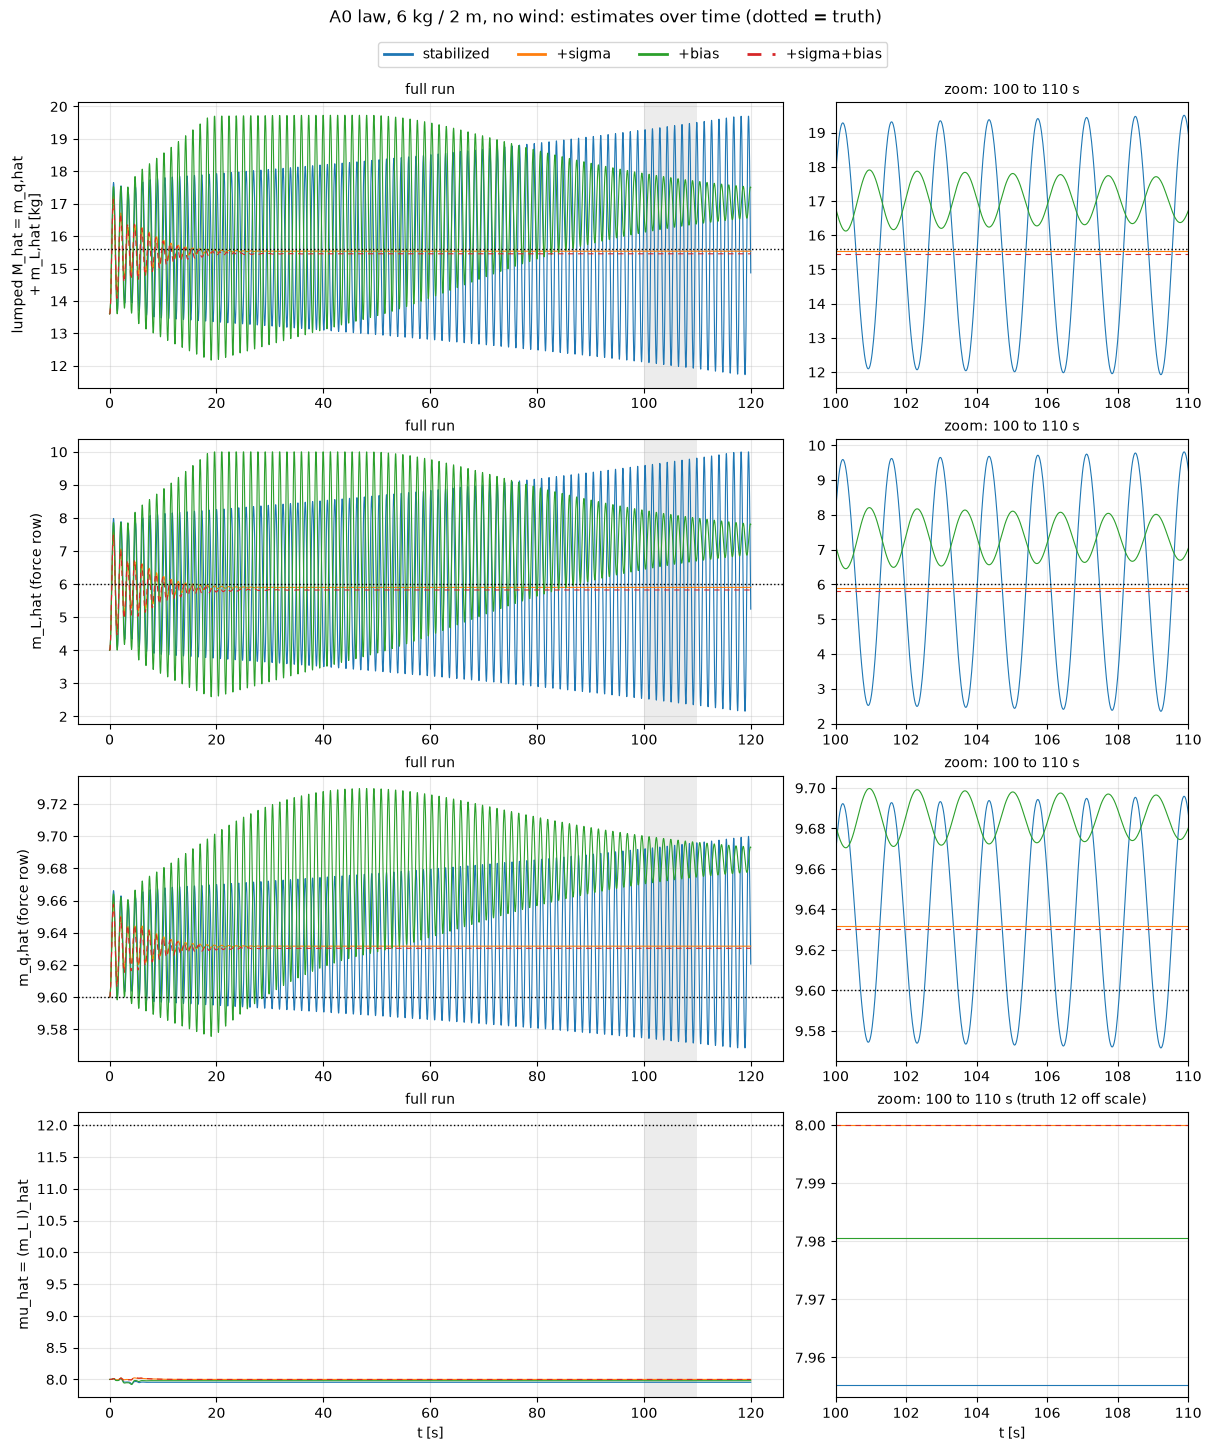

In [11]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
runs = {"stabilized": "mrac_scopeA_sigma_bias_wind_20261125/stabilized_none/a0_online.csv",
        "+sigma": "mrac_scopeA_sigma_bias_wind_20261125/stabilized_sigma_none/a0_online.csv",
        "+bias": "mrac_scopeA_sigma_bias_wind_20261125/stabilized_bias_none/a0_online.csv",
        "+sigma+bias": "mrac_scopeA_sigma_bias_wind_20261125/stabilized_sigma_bias_none/a0_online.csv"}
frames = {name: pd.read_csv(Path("results") / rel) for name, rel in runs.items()}
panels = [("lumped M_hat = m_q,hat\n+ m_L,hat [kg]", lambda d: d.estimate_mq_p + d.estimate_mL_p, 15.6),
          ("m_L,hat (force row)", lambda d: d.estimate_mL_p, 6.0),
          ("m_q,hat (force row)", lambda d: d.estimate_mq_p, 9.6),
          ("mu_hat = (m_L l)_hat", lambda d: d.estimate_mu_p, 12.0)]
ZOOM = (100, 110)
fig = plt.figure(figsize=(12, 14.4), layout="constrained")
gs = fig.add_gridspec(5, 2, height_ratios=[0.14, 1, 1, 1, 1], width_ratios=[2, 1])
legend_ax = fig.add_subplot(gs[0, :]); legend_ax.axis("off")  # own row for the shared legend, so it cannot cover the title or data
ax = [[fig.add_subplot(gs[r + 1, c]) for c in range(2)] for r in range(4)]
for row, ((full, zoom), (ylabel, value, truth)) in enumerate(zip(ax, panels)):
    inside = []
    for k, (name, df) in enumerate(frames.items()):
        y = value(df)
        for a in (full, zoom):  # dashed "+sigma+bias" keeps the coincident "+sigma" trace visible
            a.plot(df.t_s, y, label=name, color=f"C{k}", lw=0.8, linestyle=(0, (5, 4)) if name == "+sigma+bias" else "-")
        inside.extend(y[(df.t_s >= ZOOM[0]) & (df.t_s <= ZOOM[1])])
    pad = 0.05 * (max(inside) - min(inside))
    lo, hi = min(inside) - pad, max(inside) + pad
    for a in (full, zoom):
        a.axhline(truth, color="k", ls=":", lw=1); a.grid(alpha=.3)
    zoom.set_xlim(*ZOOM); zoom.set_ylim(lo, hi)
    if row:
        full.sharex(ax[0][0])
    full.axvspan(*ZOOM, color="0.5", alpha=0.15, lw=0)
    full.set_ylabel(ylabel)
    full.set_title("full run", fontsize=10)
    off = "" if lo <= truth <= hi else " (truth %g off scale)" % truth
    zoom.set_title("zoom: %g to %g s" % ZOOM + off, fontsize=10)
for a in ax[-1]:
    a.set_xlabel("t [s]")
leg_handles, leg_labels = ax[0][0].get_legend_handles_labels()
legend = legend_ax.legend(leg_handles, leg_labels, loc="center", ncol=4, fontsize=10)
for line in legend.get_lines():
    line.set_linewidth(2.0)
fig.suptitle("A0 law, 6 kg / 2 m, no wind: estimates over time (dotted = truth)")
df = pd.read_csv(Path("results") / runs["stabilized"])
Y = df[["Yp_0_0", "Yp_0_1", "Yp_0_2", "Yp_1_0", "Yp_1_1", "Yp_1_2"]].to_numpy().reshape(-1, 2, 3) / np.array([10.0, 10.0, 1.0])
rows = []
for lo, hi in ((0, 10), (10, 30), (30, 60), (90, 120)):
    m = (df.t_s >= lo) & (df.t_s < hi)
    G = 0.02 * np.einsum("kij,kil->jl", Y[m.to_numpy()], Y[m.to_numpy()])
    rows.append(dict(window=f"{lo}-{hi} s", gram_eigs=np.round(np.linalg.eigvalsh(G), 4)))
display(pd.DataFrame(rows))